# Masked Autoencoders, Variational Autoencoders, Denoising Diffusion and Retrieval-Augmented Generation

**Implementation notebook for the module assignment**

| | |
|---|---|
| Group members | Member 1 (Roll No.), Member 2 (Roll No.) |
| Course | Generative AI |
| Datasets | EuroSAT RGB, UHaT (Urdu handwritten characters), BioASQ (mini) |

### Abstract

This notebook contains the complete implementation of the four parts of the assignment. Part A pretrains a small vision transformer as a masked autoencoder (MAE) on unlabelled EuroSAT tiles and evaluates the frozen encoder with a linear classifier trained on only 160 labelled images. Part B trains a convolutional variational autoencoder (VAE) with a Bernoulli decoder on Urdu handwritten characters. Part C trains a class-conditional denoising diffusion probabilistic model (DDPM) that writes a requested Urdu character from pure noise. Part D builds a retrieval-augmented generation (RAG) system over 40k PubMed abstracts using a bi-encoder retriever and a small instruction-tuned language model, and evaluates both the retrieval and the generated answers. All models in Parts A to C are trained from random initialisation; the noise schedule, the diffusion training objective and the sampling loop, the masking, the ELBO, the vector index, the search and all evaluation metrics are written from first principles.

### Contents

1. Introduction
2. Environment and configuration
3. Task 0 – Verification of the starter code
4. Part A – Masked autoencoder on satellite images
5. Part B – Variational autoencoder on Urdu handwriting
6. Part C – Denoising diffusion: writing a requested character
7. Part D – Retrieval-augmented generation for biomedical questions
8. Human evaluation
9. Consolidated results (Tables 1–5)
10. Analysis (E.1–E.7)
11. Reproducibility notes

## 1. Introduction

The four parts are independent and may be executed in any order once Section 2 has been run. Each part writes its figures and tables to `results/` and its trained weights to `weights/`. Model definitions are written to the part folders required by the repository layout (`part_a_mae/`, `part_b_vae/`, `part_c_diffusion/`, `part_d_rag/`) so that the same code is imported by the notebook and, later, by the web application.

**Library constraints.** In line with the assignment rules, only the following external building blocks are used: `nn.TransformerEncoderLayer` / `nn.TransformerEncoder` (Part A), a randomly initialised `diffusers.UNet2DModel` (Part C, architecture only), and `AutoTokenizer`, `AutoModel`, `AutoModelForCausalLM`, `generate` and `apply_chat_template` from `transformers` (Part D only). No pretrained weights are used in Parts A–C. No diffusers scheduler or pipeline, `timm`, `sentence-transformers`, vector database or `scikit-learn` is imported anywhere; the confusion matrix, retrieval metrics and the nearest-neighbour search are implemented directly in PyTorch.

**Hardware.** The notebook is intended to run on a single CUDA GPU (e.g. a Colab or Kaggle T4). Mixed precision is used for training when a GPU is available.

## 2. Environment and configuration

### 2.1 Package installation

In [1]:
%pip install -q torch transformers datasets diffusers rouge-score matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


### 2.2 Starter code

The starter files are written to `starter/` exactly as provided in the appendix of the assignment and are not modified.

In [2]:
import os
os.makedirs("starter", exist_ok=True)

In [3]:
%%writefile starter/eurosat.py
"""Part A data: EuroSAT RGB satellite tiles (64x64, 10 land-cover classes)."""
import numpy as np
import torch
from datasets import load_dataset

EUROSAT_REPO = "blanchon/EuroSAT_RGB"
CLASS_NAMES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
               "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
PATCH = 8                                   # 64 / 8 = 8 x 8 = 64 patches per image

def load_eurosat_split(split):
    """split in {'train', 'validation', 'test'}.
    Returns images (N, 3, 64, 64) float32 in [0, 1] and labels (N,) int64."""
    ds = load_dataset(EUROSAT_REPO, split=split)
    imgs = np.stack([np.asarray(im.convert("RGB"), dtype=np.uint8) for im in ds["image"]])
    images = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255.0
    labels = torch.tensor(ds["label"], dtype=torch.long)
    return images, labels

def few_label_indices(labels, per_class=16, seed=42):
    """Indices of a fixed labelled subset: `per_class` images of each class.
    Every group gets the same 160 images."""
    rng = np.random.default_rng(seed)
    idx = []
    for c in range(len(CLASS_NAMES)):
        members = np.flatnonzero(labels.numpy() == c)
        idx.extend(rng.choice(members, size=per_class, replace=False).tolist())
    return torch.tensor(sorted(idx))

def patchify(images, p=PATCH):
    """(N, C, H, W) -> (N, L, p*p*C) with L = (H/p)*(W/p), patches in row-major order."""
    N, C, H, W = images.shape
    x = images.reshape(N, C, H // p, p, W // p, p)
    x = x.permute(0, 2, 4, 3, 5, 1)                 # N, H/p, W/p, p, p, C
    return x.reshape(N, (H // p) * (W // p), p * p * C)

def unpatchify(patches, p=PATCH, C=3):
    """Inverse of patchify: (N, L, p*p*C) -> (N, C, H, W)."""
    N, L, _ = patches.shape
    h = w = int(L ** 0.5)
    x = patches.reshape(N, h, w, p, p, C).permute(0, 5, 1, 3, 2, 4)
    return x.reshape(N, C, h * p, w * p)

Writing starter/eurosat.py


In [4]:
%%writefile starter/uhat.py
"""Parts B and C data: UHaT handwritten Urdu characters (28x28, grayscale).
Unzip data.zip from Zenodo (or the Kaggle copy) into data/uhat/ first."""
from pathlib import Path
import numpy as np
import torch
from PIL import Image

IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def _find_split_dir(root, kind, split):
    """Find the folder whose name mentions both `kind` ('char'/'digit') and
    `split` ('train'/'test') and that contains one sub-folder per class."""
    for d in sorted(Path(root).rglob("*")):
        name = d.name.lower()
        if d.is_dir() and kind in name and split in name:
            if any(c.is_dir() for c in d.iterdir()):
                return d
    found = [str(d) for d in Path(root).rglob("*") if d.is_dir()][:20]
    raise FileNotFoundError(f"No '{kind}'/'{split}' folder under {root}. Folders seen: {found}")

def load_uhat_characters(root="data/uhat", split="train", class_names=None):
    """Returns images (N, 1, 28, 28) float32 in [0, 1] with WHITE strokes on a
    BLACK background, labels (N,) int64, and the list of class names.
    Pass the training class_names when loading 'test' so labels match."""
    split_dir = _find_split_dir(root, "char", split)
    if class_names is None:
        class_names = sorted(c.name.lower() for c in split_dir.iterdir() if c.is_dir())
    index = {name: i for i, name in enumerate(class_names)}
    images, labels = [], []
    for cdir in sorted(split_dir.iterdir()):
        if not cdir.is_dir() or cdir.name.lower() not in index:
            continue
        for f in sorted(cdir.iterdir()):
            if f.suffix.lower() in IMG_EXT:
                im = Image.open(f).convert("L").resize((28, 28))
                images.append(np.asarray(im, dtype=np.float32) / 255.0)
                labels.append(index[cdir.name.lower()])
    x = torch.from_numpy(np.stack(images)).unsqueeze(1)
    # Make polarity consistent: if most pixels are bright, the background is
    # white, so invert to get white strokes on black.
    flip = x.mean(dim=(1, 2, 3)) > 0.5
    x[flip] = 1.0 - x[flip]
    return x, torch.tensor(labels, dtype=torch.long), class_names

Writing starter/uhat.py


In [5]:
%%writefile starter/bioasq.py
"""Part D data: biomedical questions + PubMed abstracts (BioASQ, mini version)."""
from datasets import load_dataset

BIOASQ_REPO = "enelpol/rag-mini-bioasq"

def load_corpus():
    """Returns {passage_id (int): passage text (str)} for all 40k abstracts."""
    ds = load_dataset(BIOASQ_REPO, "text-corpus")
    split = list(ds.keys())[0]                      # the corpus has a single split
    return {int(r["id"]): r["passage"] for r in ds[split] if r["passage"]}

def load_questions(split="test", corpus=None):
    """Returns a list of dicts: {qid, question, answer, relevant_ids}.
    relevant_ids = the ids of the abstracts that answer the question (the
    ground truth for measuring retrieval). If `corpus` is given, ids that are
    not in the corpus are dropped, and questions left with none are skipped."""
    ds = load_dataset(BIOASQ_REPO, "question-answer-passages", split=split)
    out = []
    for r in ds:
        rel = [int(i) for i in r["relevant_passage_ids"]]
        if corpus is not None:
            rel = [i for i in rel if i in corpus]
        if rel:
            out.append({"qid": int(r["id"]), "question": r["question"],
                        "answer": r["answer"], "relevant_ids": rel})
    return out

Writing starter/bioasq.py


In [6]:
%%writefile starter/viz.py
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

def save_grid(images, path, nrow=8, titles=None):
    """images: (N, C, H, W) in [0, 1]. Saves an nrow-wide grid to `path`."""
    images = images.detach().cpu().clamp(0, 1)
    n = images.shape[0]
    rows = (n + nrow - 1) // nrow
    fig, axes = plt.subplots(rows, nrow, figsize=(1.4 * nrow, 1.4 * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            img = images[i].permute(1, 2, 0).numpy()
            ax.imshow(img.squeeze(-1) if img.shape[-1] == 1 else img, cmap="gray", vmin=0, vmax=1)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

Writing starter/viz.py


In [7]:
%%writefile starter/check_starter.py
import os
import torch
from viz import save_grid
from eurosat import load_eurosat_split, few_label_indices, patchify, unpatchify, CLASS_NAMES
from uhat import load_uhat_characters
from bioasq import load_corpus, load_questions

os.makedirs("results", exist_ok=True)

# ---- Part A: EuroSAT ----
x_tr, y_tr = load_eurosat_split("train")
x_te, y_te = load_eurosat_split("test")
few = few_label_indices(y_tr)
p = patchify(x_tr[:8])
print("EuroSAT train", tuple(x_tr.shape), "test", tuple(x_te.shape))
print("few-label subset:", len(few), "images; patches per image:", tuple(p.shape))
assert torch.equal(unpatchify(p), x_tr[:8])
save_grid(x_tr[:32], "results/eurosat_examples.png", nrow=8,
          titles=[CLASS_NAMES[i] for i in y_tr[:32]])

# ---- Parts B and C: UHaT characters ----
c_tr, l_tr, names = load_uhat_characters(split="train")
c_te, l_te, _ = load_uhat_characters(split="test", class_names=names)
print("UHaT train", tuple(c_tr.shape), "test", tuple(c_te.shape), "classes:", len(names))
print("class names:", names)
pick = torch.randperm(len(c_tr))[:64]
save_grid(c_tr[pick], "results/uhat_examples.png", nrow=8, titles=[names[i] for i in l_tr[pick]])

# ---- Part D: BioASQ ----
corpus = load_corpus()
qs = load_questions("test", corpus)
print("BioASQ corpus:", len(corpus), "abstracts; test questions:", len(qs))
print("example:", qs[0]["question"], "| relevant ids:", qs[0]["relevant_ids"][:5])

Writing starter/check_starter.py


### 2.3 Imports and shared utilities

In [8]:
import os, sys, json, time, math, random, re, csv, copy, zipfile, shutil, subprocess, urllib.request
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, Markdown, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "starter"))
sys.path.insert(0, str(ROOT))

from viz import save_grid
from eurosat import load_eurosat_split, few_label_indices, patchify, unpatchify, CLASS_NAMES
from uhat import load_uhat_characters
from bioasq import load_corpus, load_questions

RESULTS = ROOT / "results"
WEIGHTS = ROOT / "weights"
for d in [RESULTS, WEIGHTS, ROOT / "part_a_mae", ROOT / "part_b_vae",
          ROOT / "part_c_diffusion", ROOT / "part_d_rag", ROOT / "app"]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print(f"torch {torch.__version__} | device: {DEVICE} ({GPU_NAME})")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def autocast():
    """Mixed precision on the GPU, a no-op on the CPU."""
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)


def show(path, width=None):
    display(IPImage(filename=str(path), width=width))


def savefig(fig, name, width=None):
    path = RESULTS / name
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.close(fig)
    show(path, width)
    return path


def count_params(module):
    return sum(p.numel() for p in module.parameters())


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


REPORT = {}   # collects every number that goes into Tables 1-5 and the analysis

torch 2.11.0+cu130 | device: cuda (Tesla T4)


### 2.4 Run configuration

All training hyperparameters fixed by the assignment are set inside the respective sections. The values below control the overall run. `SMOKE_TEST = True` shrinks every dataset and every training run so that the whole notebook can be checked end to end in a few minutes; it must be `False` for the reported results.

In [9]:
SEED = 42
SMOKE_TEST = False

MAE_EPOCHS     = 100      # A.1 (fixed by the assignment)
PROBE_EPOCHS   = 200      # A.3 (fixed by the assignment)
VAE_EPOCHS     = 30      # B.3 (fixed by the assignment)
DDPM_EPOCHS    = 40      # C.3 (fixed by the assignment)
RAG_N_GENERATE = 100      # D.6 (fixed by the assignment)

RETRIEVER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
GENERATOR_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
UHAT_ROOT = ROOT / "starter" / "data" / "uhat"

if SMOKE_TEST:
    MAE_EPOCHS, PROBE_EPOCHS, VAE_EPOCHS, DDPM_EPOCHS, RAG_N_GENERATE = 1, 5, 1, 1, 4

seed_everything(SEED)

## 3. Task 0 – Verification of the starter code

### 0.1 Data preparation and execution of `check_starter.py`

EuroSAT and BioASQ are downloaded automatically from the Hugging Face Hub. UHaT is downloaded from Zenodo and extracted into `starter/data/uhat/` if it is not already present (Appendix A.2).

In [10]:
UHAT_URL = "https://zenodo.org/records/3670611/files/data.zip?download=1"

def uhat_present(root):
    root = Path(root)
    return root.exists() and any(p.is_dir() and "char" in p.name.lower() and "train" in p.name.lower()
                                 for p in root.rglob("*"))

if not uhat_present(UHAT_ROOT):
    UHAT_ROOT.mkdir(parents=True, exist_ok=True)
    archive = UHAT_ROOT / "data.zip"
    print("Downloading UHaT from Zenodo ...")
    urllib.request.urlretrieve(UHAT_URL, archive)
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(UHAT_ROOT)
    archive.unlink()
    # some copies of the dataset contain nested archives
    for inner in list(UHAT_ROOT.rglob("*.zip")):
        with zipfile.ZipFile(inner) as zf:
            zf.extractall(inner.parent)
        inner.unlink()
print("UHaT available:", uhat_present(UHAT_ROOT))

UHaT available: True


In [11]:
t0 = time.time()
proc = subprocess.run([sys.executable, "check_starter.py"], cwd=ROOT / "starter",
                      capture_output=True, text=True)
print(proc.stdout)
if proc.returncode != 0:
    print(proc.stderr[-3000:])
    raise RuntimeError("check_starter.py failed")
(RESULTS / "task0_output.txt").write_text(proc.stdout)
print(f"check_starter.py finished in {time.time() - t0:.0f} s")

EuroSAT train (16200, 3, 64, 64) test (5400, 3, 64, 64)
few-label subset: 160 images; patches per image: (8, 64, 192)
UHaT train (28328, 1, 28, 28) test (4747, 1, 28, 28) classes: 40
class names: ['alif', 'alif mad aa', 'ayn', 'baa', 'bari yaa', 'cheey', 'choti yaa', 'daal', 'dhaal', 'faa', 'gaaf', 'ghain', 'haa1', 'haa2', 'haa3', 'hamza', 'jeem', 'kaaf', 'khaa', 'laam', 'meem', 'noon', 'noonghunna', 'paa', 'qaaf', 'raa', 'rhraa', 'seen', 'seey', 'sheen', 'swaad', 'taa', 'ttaa', 'twa', 'waw', 'zaaa', 'zaal', 'zhaa', 'zwaa', 'zwaad']
BioASQ corpus: 40181 abstracts; test questions: 707
example: Is capmatinib effective for glioblastoma? | relevant ids: [31776899]

check_starter.py finished in 34 s


### 0.2 Reported shapes and example grids

The printed output above is stored in `results/task0_output.txt`. The two grids saved by the script are copied to `results/` and shown below.

eurosat_examples.png


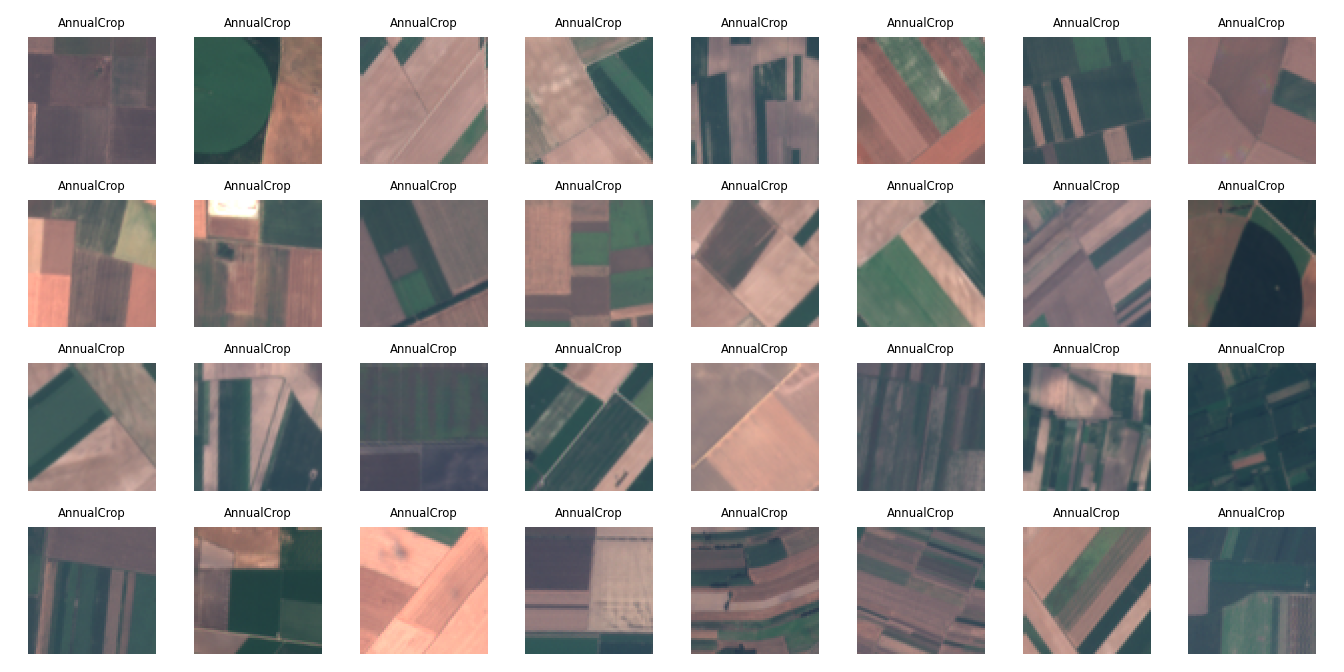

uhat_examples.png


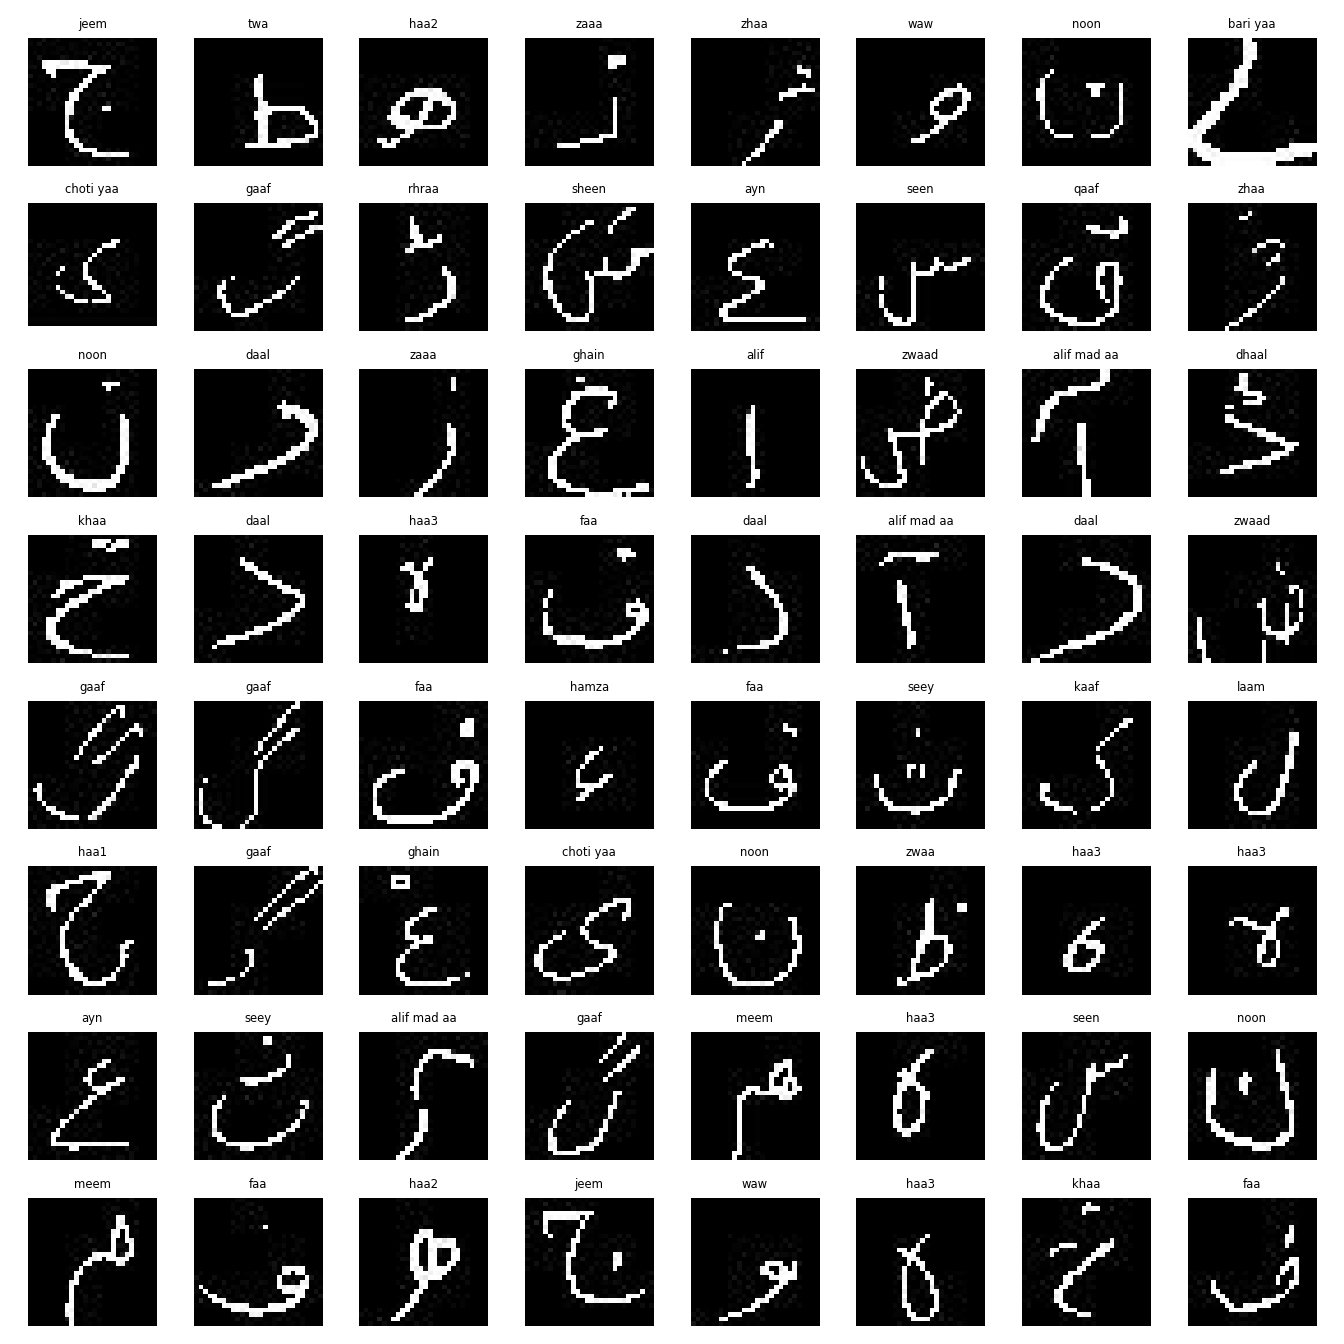

In [12]:
for name in ["eurosat_examples.png", "uhat_examples.png"]:
    shutil.copy(ROOT / "starter" / "results" / name, RESULTS / name)
    print(name)
    show(RESULTS / name, width=700)

## 4. Part A – Masked autoencoder on satellite images

Each 64 × 64 tile is divided into 64 non-overlapping 8 × 8 patches of 192 values. During pretraining, 75 % of the patches (48 of 64) are removed at random, the encoder processes only the 16 visible patches, and a lightweight decoder reconstructs the pixels of every patch from the encoded visible patches and a learned mask token. The loss is the mean squared error on the masked patches only.

### 4.1 Data

In [13]:
x_tr, y_tr = load_eurosat_split("train")
x_va, y_va = load_eurosat_split("validation")
x_te, y_te = load_eurosat_split("test")
few_idx = few_label_indices(y_tr)

x_pre = x_tr[:512] if SMOKE_TEST else x_tr          # labels are not used for pretraining
print("train", tuple(x_tr.shape), "| validation", tuple(x_va.shape), "| test", tuple(x_te.shape))
print("labelled subset:", len(few_idx), "images, per class:",
      torch.bincount(y_tr[few_idx], minlength=10).tolist())
REPORT["eurosat"] = dict(train=len(x_tr), test=len(x_te), labelled=len(few_idx))

train (16200, 3, 64, 64) | validation (5400, 3, 64, 64) | test (5400, 3, 64, 64)
labelled subset: 160 images, per class: [16, 16, 16, 16, 16, 16, 16, 16, 16, 16]


### 4.2 Model

The architecture follows the specification exactly:

| Component | Specification |
|---|---|
| Patch embedding | `nn.Linear(192, 192)` |
| Positional embedding | learned, 64 × 192, added to every patch |
| Masking | 75 %, 16 visible patches, new random choice per image and per step |
| Encoder | 6 × `nn.TransformerEncoderLayer` (width 192, 3 heads, feed-forward 768) on visible patches, then `LayerNorm` |
| Decoder | `nn.Linear(192, 128)`, learned mask token, learned 64 × 128 positional embedding, 2 × `nn.TransformerEncoderLayer` (width 128, 4 heads), `nn.Linear(128, 192)` |
| Loss | MSE on masked patches only |

Pre-norm layers with GELU activations and no dropout are used, as in the original MAE. The decoder feed-forward width is not specified and is set to 4 × 128 = 512. Masking is implemented by sorting per-image uniform noise: the first 16 indices of the permutation are kept, and the inverse permutation restores the original patch order in the decoder.

In [14]:
%%writefile part_a_mae/model.py
"""Masked autoencoder for 64x64 EuroSAT tiles (64 patches of 8x8x3)."""
import torch
import torch.nn as nn


def _transformer(width, heads, ff, depth):
    layer = nn.TransformerEncoderLayer(width, heads, ff, dropout=0.0, activation="gelu",
                                       batch_first=True, norm_first=True)
    return nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)


class MAE(nn.Module):
    def __init__(self, num_patches=64, patch_dim=192, enc_dim=192, enc_depth=6, enc_heads=3,
                 enc_ff=768, dec_dim=128, dec_depth=2, dec_heads=4, dec_ff=512, mask_ratio=0.75):
        super().__init__()
        self.num_patches = num_patches
        self.n_keep = int(round(num_patches * (1 - mask_ratio)))

        self.patch_embed = nn.Linear(patch_dim, enc_dim)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, enc_dim))
        self.encoder = _transformer(enc_dim, enc_heads, enc_ff, enc_depth)
        self.enc_norm = nn.LayerNorm(enc_dim)

        self.dec_embed = nn.Linear(enc_dim, dec_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, dec_dim))
        self.dec_pos_embed = nn.Parameter(torch.zeros(1, num_patches, dec_dim))
        self.decoder = _transformer(dec_dim, dec_heads, dec_ff, dec_depth)
        self.dec_pred = nn.Linear(dec_dim, patch_dim)
        self._init_weights()

    def _init_weights(self):
        for p in (self.pos_embed, self.dec_pos_embed, self.mask_token):
            nn.init.trunc_normal_(p, std=0.02)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def random_masking(self, x):
        """x: (N, L, D). Keeps n_keep random tokens per image.
        Returns visible tokens, the binary mask (1 = masked) and the inverse permutation."""
        N, L, D = x.shape
        noise = torch.rand(N, L, device=x.device)
        ids_shuffle = noise.argsort(dim=1)
        ids_restore = ids_shuffle.argsort(dim=1)
        ids_keep = ids_shuffle[:, :self.n_keep]
        x_visible = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
        mask = torch.ones(N, L, device=x.device)
        mask[:, :self.n_keep] = 0
        mask = torch.gather(mask, 1, ids_restore)
        return x_visible, mask, ids_restore

    def forward_encoder(self, patches):
        x = self.patch_embed(patches) + self.pos_embed
        x, mask, ids_restore = self.random_masking(x)
        return self.enc_norm(self.encoder(x)), mask, ids_restore

    def forward_decoder(self, latent, ids_restore):
        x = self.dec_embed(latent)
        N, n_vis, C = x.shape
        mask_tokens = self.mask_token.expand(N, ids_restore.shape[1] - n_vis, -1)
        x = torch.cat([x, mask_tokens], dim=1)
        x = torch.gather(x, 1, ids_restore.unsqueeze(-1).expand(-1, -1, C))   # original order
        x = self.decoder(x + self.dec_pos_embed)
        return self.dec_pred(x)

    @staticmethod
    def masked_mse(pred, target, mask):
        per_patch = ((pred.float() - target.float()) ** 2).mean(dim=-1)
        return (per_patch * mask).sum() / mask.sum()

    def forward(self, patches):
        latent, mask, ids_restore = self.forward_encoder(patches)
        pred = self.forward_decoder(latent, ids_restore)
        return self.masked_mse(pred, patches, mask), pred, mask

    def features(self, patches):
        """All 64 patches, no masking; average of the encoder outputs -> (N, 192)."""
        x = self.patch_embed(patches) + self.pos_embed
        return self.enc_norm(self.encoder(x)).mean(dim=1)


class LinearProbe(nn.Module):
    def __init__(self, dim=192, num_classes=10):
        super().__init__()
        self.fc = nn.Linear(dim, num_classes)

    def forward(self, f):
        return self.fc(f)

Writing part_a_mae/model.py


In [15]:
import importlib, part_a_mae.model as _ma
importlib.reload(_ma)
from part_a_mae.model import MAE, LinearProbe

seed_everything(SEED)
mae = MAE().to(DEVICE)
n_enc = sum(p.numel() for n, p in mae.named_parameters()
            if n.startswith(("patch_embed", "pos_embed", "encoder", "enc_norm")))
print(f"MAE parameters: {count_params(mae):,} (encoder {n_enc:,}, decoder {count_params(mae) - n_enc:,})")

MAE parameters: 3,173,248 (encoder 2,718,912, decoder 454,336)


### 4.3 Correctness checks

The checks below confirm that exactly 48 of 64 patches are masked in every image, that a new mask is drawn for every image and every call, and that the loss depends only on the masked patches: changing the predictions at visible positions leaves the loss unchanged and their gradient is exactly zero.

In [16]:
checks_a = []
patches = patchify(x_tr[:256]).to(DEVICE)
with torch.no_grad():
    loss, pred, mask = mae(patches)
    _, _, mask2 = mae(patches)

n_masked = mask.sum(dim=1)
checks_a.append(f"masked patches per image: min {int(n_masked.min())}, max {int(n_masked.max())} (expected 48 of 64)")
assert torch.all(n_masked == 48)

unique_masks = len({tuple(m.tolist()) for m in mask.bool().cpu()})
checks_a.append(f"distinct masks among 256 images: {unique_masks}; identical masks between two calls: "
                f"{int((mask == mask2).all(dim=1).sum())} of 256")

visible = mask == 0
pred_changed = pred.clone()
pred_changed[visible] = torch.randn_like(pred_changed[visible]) * 10.0
l_orig = MAE.masked_mse(pred, patches, mask)
l_changed = MAE.masked_mse(pred_changed, patches, mask)
checks_a.append(f"loss before / after corrupting visible-patch predictions: {l_orig:.6f} / {l_changed:.6f}")
assert torch.allclose(l_orig, l_changed)

p_req = pred.detach().clone().requires_grad_(True)
MAE.masked_mse(p_req, patches, mask).backward()
g_vis, g_mask = p_req.grad[visible].abs().max().item(), p_req.grad[~visible].abs().max().item()
checks_a.append(f"max |grad| at visible patches = {g_vis:.1e}, at masked patches = {g_mask:.1e}")
assert g_vis == 0 and g_mask > 0

print("\n".join(checks_a))
REPORT["checks_a"] = checks_a

masked patches per image: min 48, max 48 (expected 48 of 64)
distinct masks among 256 images: 256; identical masks between two calls: 0 of 256
loss before / after corrupting visible-patch predictions: 1.104597 / 1.104597
max |grad| at visible patches = 0.0e+00, at masked patches = 3.0e-06


### 4.4 A.1 Pretraining

AdamW with learning rate 5 × 10⁻⁴, weight decay 0.05 and batch size 256 for 100 epochs on the 16.2k training images, labels ignored. The masked-patch loss on the validation split is logged alongside the training loss.

In [17]:
def mae_epoch(model, data, opt=None, scaler=None, bs=256):
    train = opt is not None
    model.train(train)
    perm = torch.randperm(len(data), device=data.device) if train else torch.arange(len(data), device=data.device)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for i in range(0, len(data), bs):
            xb = patchify(data[perm[i:i + bs]])
            with autocast():
                loss, _, _ = model(xb)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
            total += loss.item() * len(xb)
            n += len(xb)
    return total / n


seed_everything(SEED)
mae = MAE().to(DEVICE)
opt = torch.optim.AdamW(mae.parameters(), lr=5e-4, weight_decay=0.05)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
train_gpu, val_gpu = x_pre.to(DEVICE), x_va.to(DEVICE)

mae_hist = {"train": [], "val": []}
sync(); t0 = time.time()
for ep in range(1, MAE_EPOCHS + 1):
    mae_hist["train"].append(mae_epoch(mae, train_gpu, opt, scaler))
    mae_hist["val"].append(mae_epoch(mae, val_gpu))
    if ep == 1 or ep % 10 == 0 or ep == MAE_EPOCHS:
        print(f"epoch {ep:3d} | train masked MSE {mae_hist['train'][-1]:.5f} | val {mae_hist['val'][-1]:.5f}")
sync(); mae_time = time.time() - t0
print(f"pretraining time: {mae_time / 60:.1f} min on {GPU_NAME}")

REPORT["mae_train"] = dict(params=count_params(mae), final_loss=mae_hist["train"][-1],
                           val_loss=mae_hist["val"][-1], time_min=mae_time / 60)
json.dump(mae_hist, open(RESULTS / "mae_loss_history.json", "w"))
del train_gpu, val_gpu

epoch   1 | train masked MSE 0.08959 | val 0.02351
epoch  10 | train masked MSE 0.00831 | val 0.00837
epoch  20 | train masked MSE 0.00787 | val 0.00807
epoch  30 | train masked MSE 0.00770 | val 0.00777
epoch  40 | train masked MSE 0.00758 | val 0.00771
epoch  50 | train masked MSE 0.00755 | val 0.00782
epoch  60 | train masked MSE 0.00752 | val 0.00788
epoch  70 | train masked MSE 0.00720 | val 0.00754
epoch  80 | train masked MSE 0.00718 | val 0.00738
epoch  90 | train masked MSE 0.00708 | val 0.00722
epoch 100 | train masked MSE 0.00671 | val 0.00687
pretraining time: 3.7 min on Tesla T4


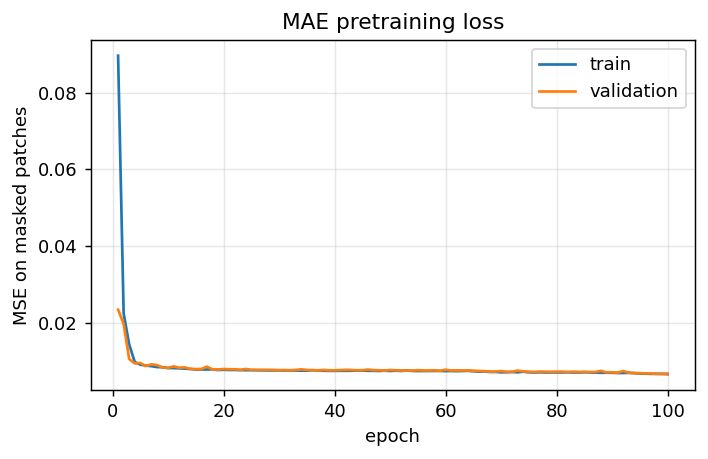

PosixPath('/kaggle/working/results/mae_pretraining_loss.png')

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ep = np.arange(1, len(mae_hist["train"]) + 1)
ax.plot(ep, mae_hist["train"], label="train")
ax.plot(ep, mae_hist["val"], label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE on masked patches"); ax.set_title("MAE pretraining loss")
ax.grid(alpha=0.3); ax.legend()
savefig(fig, "mae_pretraining_loss.png", width=500)

### 4.5 A.2 Reconstructions

Eight test images, one from each of eight different classes. Rows: masked input (masked patches in grey), reconstruction (predicted masked patches pasted into the visible ones), original.

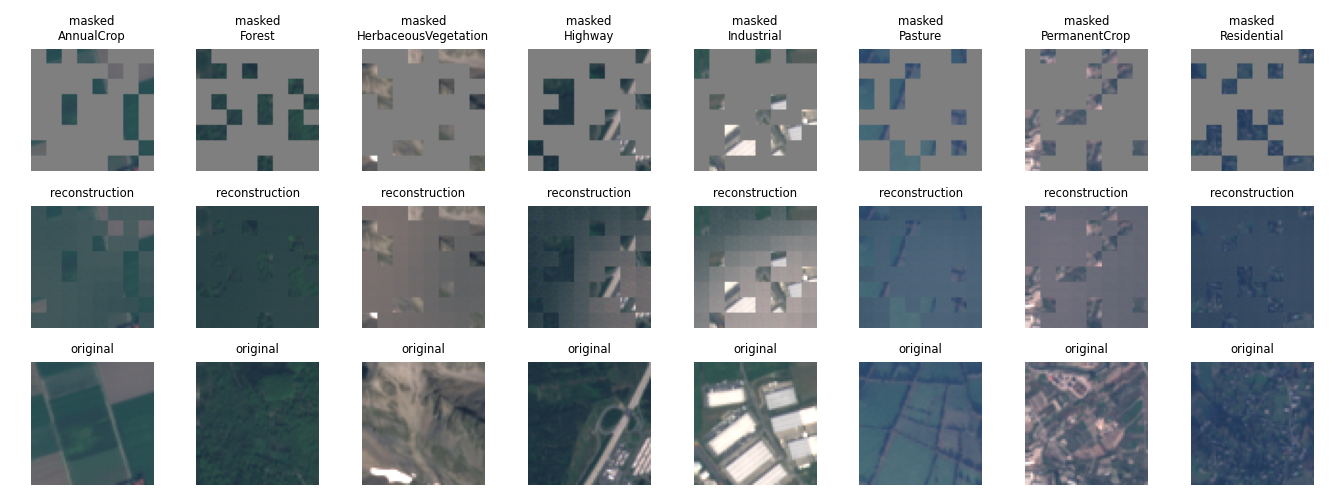

In [19]:
mae.eval()
recon_idx = [int(torch.nonzero(y_te == c)[0]) for c in range(8)]
imgs = x_te[recon_idx].to(DEVICE)
patches = patchify(imgs)
torch.manual_seed(SEED)
with torch.no_grad():
    _, pred, mask = mae(patches)
m = mask.unsqueeze(-1)
masked_input = patches * (1 - m) + 0.5 * m
reconstruction = patches * (1 - m) + pred.float().clamp(0, 1) * m
grid = torch.cat([unpatchify(masked_input), unpatchify(reconstruction), imgs])
titles = [f"masked\n{CLASS_NAMES[y_te[i]]}" for i in recon_idx] + ["reconstruction"] * 8 + ["original"] * 8
save_grid(grid, RESULTS / "mae_reconstructions.png", nrow=8, titles=titles)
show(RESULTS / "mae_reconstructions.png", width=750)

### 4.6 A.3 Few-label linear classifier

The encoder is frozen. Each image is encoded without masking, the 64 encoder outputs are averaged into a 192-dimensional feature, and `nn.Linear(192, 10)` is trained with cross-entropy on the 160 labelled images (AdamW, learning rate 10⁻³, 200 epochs, a single batch of 160).

In [20]:
@torch.no_grad()
def extract_features(model, images, bs=512):
    model.eval()
    feats = []
    for i in range(0, len(images), bs):
        with autocast():
            f = model.features(patchify(images[i:i + bs].to(DEVICE)))
        feats.append(f.float().cpu())
    return torch.cat(feats)


for p in mae.parameters():
    p.requires_grad_(False)

f_few, y_few = extract_features(mae, x_tr[few_idx]).to(DEVICE), y_tr[few_idx].to(DEVICE)
f_te = extract_features(mae, x_te).to(DEVICE)

seed_everything(SEED)
probe = LinearProbe().to(DEVICE)
opt = torch.optim.AdamW(probe.parameters(), lr=1e-3)
probe_hist = []
for ep in range(1, PROBE_EPOCHS + 1):
    loss = F.cross_entropy(probe(f_few), y_few)
    opt.zero_grad(); loss.backward(); opt.step()
    probe_hist.append(loss.item())
    if ep == 1 or ep % 50 == 0 or ep == PROBE_EPOCHS:
        acc = (probe(f_few).argmax(1) == y_few).float().mean().item()
        print(f"epoch {ep:3d} | cross-entropy {loss.item():.4f} | train accuracy {acc:.3f}")

torch.save({"mae": mae.state_dict(), "probe": probe.state_dict(), "class_names": CLASS_NAMES},
           WEIGHTS / "mae_eurosat.pt")
print("saved", WEIGHTS / "mae_eurosat.pt")

epoch   1 | cross-entropy 2.4950 | train accuracy 0.031
epoch  50 | cross-entropy 1.6228 | train accuracy 0.544
epoch 100 | cross-entropy 1.4419 | train accuracy 0.538
epoch 150 | cross-entropy 1.3532 | train accuracy 0.556
epoch 200 | cross-entropy 1.2990 | train accuracy 0.562
saved /kaggle/working/weights/mae_eurosat.pt


### 4.7 A.4 Test accuracy and confusion matrix

In [21]:
def confusion_matrix(y_true, y_pred, n):
    return torch.bincount(y_true * n + y_pred, minlength=n * n).reshape(n, n)

with torch.no_grad():
    y_hat = probe(f_te).argmax(1).cpu()
test_acc = (y_hat == y_te).float().mean().item()
cm = confusion_matrix(y_te, y_hat, 10)
per_class = (cm.diag() / cm.sum(1).clamp(min=1)).tolist()

print(f"Test accuracy on {len(y_te)} images: {100 * test_acc:.2f} %  (chance: 10 %)\n")
for c, a in zip(CLASS_NAMES, per_class):
    print(f"  {c:22s} {100 * a:6.2f} %")

off = cm.clone().float(); off.fill_diagonal_(0)
pairs = []
for i in range(10):
    for j in range(i + 1, 10):
        pairs.append((int(off[i, j] + off[j, i]), CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j]), int(off[j, i])))
pairs.sort(reverse=True)
print("\nMost frequently confused pairs (both directions):")
for tot, a, b, ab, ba in pairs[:5]:
    print(f"  {a} <-> {b}: {tot}  ({a}->{b}: {ab}, {b}->{a}: {ba})")

REPORT["mae_probe"] = dict(test_acc=test_acc, per_class=dict(zip(CLASS_NAMES, per_class)),
                           confused=pairs[:5], cm=cm.tolist())
np.savetxt(RESULTS / "mae_confusion_matrix.csv", cm.numpy(), fmt="%d", delimiter=",",
           header=",".join(CLASS_NAMES), comments="")

Test accuracy on 5400 images: 46.57 %  (chance: 10 %)

  AnnualCrop              24.83 %
  Forest                  70.89 %
  HerbaceousVegetation    47.64 %
  Highway                 20.56 %
  Industrial              72.06 %
  Pasture                 60.61 %
  PermanentCrop           44.05 %
  Residential             40.79 %
  River                   31.19 %
  SeaLake                 54.52 %

Most frequently confused pairs (both directions):
  AnnualCrop <-> PermanentCrop: 248  (AnnualCrop->PermanentCrop: 197, PermanentCrop->AnnualCrop: 51)
  HerbaceousVegetation <-> PermanentCrop: 216  (HerbaceousVegetation->PermanentCrop: 89, PermanentCrop->HerbaceousVegetation: 127)
  Pasture <-> River: 170  (Pasture->River: 67, River->Pasture: 103)
  Highway <-> River: 167  (Highway->River: 79, River->Highway: 88)
  Pasture <-> SeaLake: 151  (Pasture->SeaLake: 0, SeaLake->Pasture: 151)


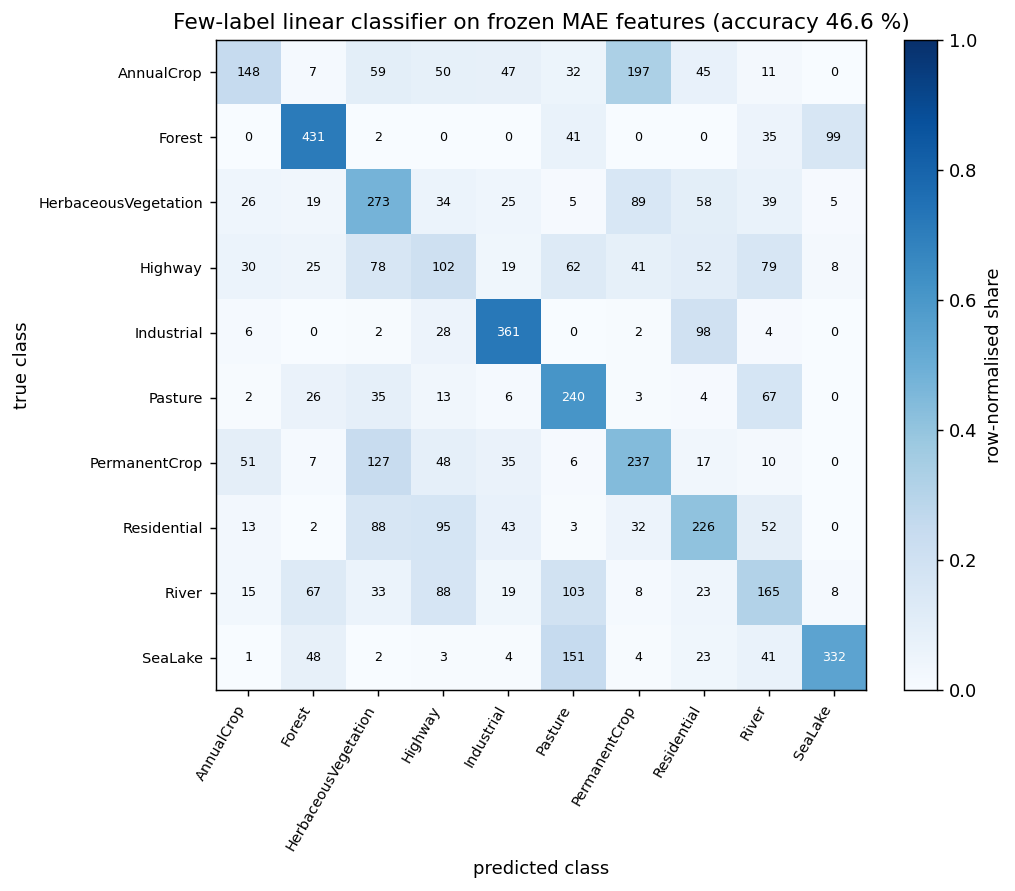

PosixPath('/kaggle/working/results/mae_confusion_matrix.png')

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
cm_norm = (cm / cm.sum(1, keepdim=True).clamp(min=1)).numpy()
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.set_title(f"Few-label linear classifier on frozen MAE features (accuracy {100 * test_acc:.1f} %)")
fig.colorbar(im, ax=ax, fraction=0.046, label="row-normalised share")
savefig(fig, "mae_confusion_matrix.png", width=560)

## 5. Part B – Variational autoencoder on Urdu handwriting

The 40 character classes of UHaT are used with pixel values in [0, 1] (white strokes on black). Labels are not used.

### 5.1 Data

In [23]:
c_tr, l_tr, uhat_names = load_uhat_characters(root=str(UHAT_ROOT), split="train")
c_te, l_te, _ = load_uhat_characters(root=str(UHAT_ROOT), split="test", class_names=uhat_names)
if len(uhat_names) != 40:
    print(f"warning: expected 40 character classes, found {len(uhat_names)}")
print("train", tuple(c_tr.shape), "| test", tuple(c_te.shape), "| classes:", len(uhat_names))
print("pixel range:", float(c_tr.min()), "-", float(c_tr.max()), "| mean intensity:", round(float(c_tr.mean()), 3))
REPORT["uhat"] = dict(classes=len(uhat_names), train=len(c_tr), test=len(c_te))

train (28328, 1, 28, 28) | test (4747, 1, 28, 28) | classes: 40
pixel range: 0.0 - 1.0 | mean intensity: 0.083


### 5.2 Model and objective

| Component | Specification |
|---|---|
| Encoder $q_\phi(z\mid x)$ | Conv2d(1, 32, 4, 2, 1), ReLU, Conv2d(32, 64, 4, 2, 1), ReLU, flatten (3136), two linear heads for $\mu$ and $\log\sigma^2$ (16 each) |
| Decoder $p_\theta(x\mid z)$ | Linear(16, 3136), reshape to 64 × 7 × 7, ConvTranspose2d(64, 32, 4, 2, 1), ReLU, ConvTranspose2d(32, 1, 4, 2, 1): one Bernoulli logit per pixel |

**B.1 Reparameterisation.** $z = \mu + \sigma \odot \epsilon$ with $\epsilon \sim \mathcal N(0, I)$ and $\sigma = \exp(\tfrac12 \log\sigma^2)$.

**B.2 Loss.** The negative ELBO averaged over the batch,

$$\mathcal L(\theta,\phi;x) = \underbrace{-\log p_\theta(x\mid z)}_{\text{BCE summed over 784 pixels}} \; \underbrace{-\,\frac12\sum_{j=1}^{d}\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)}_{D_{\mathrm{KL}}\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)} .$$

Both terms are measured in nats per image.

In [24]:
%%writefile part_b_vae/model.py
"""Convolutional VAE with a Bernoulli decoder for 28x28 characters."""
import torch
import torch.nn as nn
import torch.nn.functional as F


class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),
            nn.Flatten())
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)
        self.dec_fc = nn.Linear(latent_dim, 64 * 7 * 7)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1))

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    @staticmethod
    def reparameterize(mu, logvar):
        sigma = torch.exp(0.5 * logvar)
        return mu + sigma * torch.randn_like(sigma)

    def decode(self, z):
        """Returns one logit per pixel, shape (N, 1, 28, 28)."""
        return self.dec(self.dec_fc(z).view(-1, 64, 7, 7))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

    @torch.no_grad()
    def sample(self, n, device):
        z = torch.randn(n, self.latent_dim, device=device)
        return torch.sigmoid(self.decode(z))

    @torch.no_grad()
    def interpolate(self, x_a, x_b, steps=10):
        """Linear interpolation between the posterior means of two images."""
        mu_a, _ = self.encode(x_a)
        mu_b, _ = self.encode(x_b)
        w = torch.linspace(0, 1, steps, device=mu_a.device).unsqueeze(1)
        return torch.sigmoid(self.decode((1 - w) * mu_a + w * mu_b))


def kl_divergence(mu, logvar):
    """Closed-form KL(N(mu, sigma^2) || N(0, I)) per image, summed over latent dims."""
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)


def negative_elbo(logits, x, mu, logvar):
    """Returns (loss, reconstruction, kl), each averaged over the batch, in nats per image."""
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(dim=(1, 2, 3))
    kl = kl_divergence(mu, logvar)
    return (rec + kl).mean(), rec.mean(), kl.mean()

Writing part_b_vae/model.py


In [25]:
import part_b_vae.model as _mb
importlib.reload(_mb)
from part_b_vae.model import VAE, kl_divergence, negative_elbo

seed_everything(SEED)
vae = VAE(latent_dim=16).to(DEVICE)
print(f"VAE parameters: {count_params(vae):,}")

VAE parameters: 220,385


### 5.3 Correctness checks

The KL term must be zero for $\mu = 0,\ \log\sigma^2 = 0$ and non-negative for any input. The second property is checked on random parameters and is additionally monitored on every training batch.

In [26]:
checks_b = []
kl_zero = kl_divergence(torch.zeros(4, 16), torch.zeros(4, 16))
checks_b.append(f"KL at mu = 0, log sigma^2 = 0: {kl_zero.tolist()}")
assert torch.all(kl_zero == 0)

g = torch.Generator().manual_seed(0)
kl_rand = kl_divergence(torch.randn(100000, 16, generator=g) * 3, torch.randn(100000, 16, generator=g) * 3)
checks_b.append(f"KL on 100,000 random (mu, log sigma^2): min {kl_rand.min():.4f} (must be >= 0)")
assert torch.all(kl_rand >= 0)

with torch.no_grad():
    logits, mu, logvar = vae(c_tr[:8].to(DEVICE))
checks_b.append(f"encoder output {tuple(mu.shape)}, decoder output {tuple(logits.shape)}")
print("\n".join(checks_b))

KL at mu = 0, log sigma^2 = 0: [-0.0, -0.0, -0.0, -0.0]
KL on 100,000 random (mu, log sigma^2): min 29.3455 (must be >= 0)
encoder output (8, 16), decoder output (8, 1, 28, 28)


### 5.4 Training

**B.3** Adam with learning rate 10⁻³, batch size 128, 30 epochs. The reconstruction term, the KL term and their sum are logged per epoch for the training and the test set.

In [27]:
def vae_epoch(model, data, opt=None, bs=128):
    train = opt is not None
    model.train(train)
    perm = torch.randperm(len(data), device=data.device) if train else torch.arange(len(data), device=data.device)
    rec_sum = kl_sum = 0.0
    kl_min = float("inf")
    with torch.set_grad_enabled(train):
        for i in range(0, len(data), bs):
            xb = data[perm[i:i + bs]]
            logits, mu, logvar = model(xb)
            loss, rec, kl = negative_elbo(logits, xb, mu, logvar)
            if train:
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            rec_sum += rec.item() * len(xb); kl_sum += kl.item() * len(xb)
            kl_min = min(kl_min, kl_divergence(mu, logvar).min().item())
    return rec_sum / len(data), kl_sum / len(data), kl_min


seed_everything(SEED)
vae = VAE(latent_dim=16).to(DEVICE)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
tr_gpu, te_gpu = c_tr.to(DEVICE), c_te.to(DEVICE)

vae_hist = {k: [] for k in ["train_rec", "train_kl", "test_rec", "test_kl"]}
kl_min_seen = float("inf")
sync(); t0 = time.time()
for ep in range(1, VAE_EPOCHS + 1):
    rec, kl, kmin = vae_epoch(vae, tr_gpu, opt)
    trec, tkl, _ = vae_epoch(vae, te_gpu)
    kl_min_seen = min(kl_min_seen, kmin)
    for k, v in zip(vae_hist, [rec, kl, trec, tkl]):
        vae_hist[k].append(v)
    if ep == 1 or ep % 5 == 0 or ep == VAE_EPOCHS:
        print(f"epoch {ep:3d} | train rec {rec:7.2f} KL {kl:6.2f} | test rec {trec:7.2f} KL {tkl:6.2f}")
sync(); vae_time = time.time() - t0

checks_b.append(f"smallest per-image KL over all training batches: {kl_min_seen:.4f} (never negative)")
assert kl_min_seen >= 0
print(checks_b[-1])
REPORT["checks_b"] = checks_b
REPORT["vae_train"] = dict(params=count_params(vae), final_loss=vae_hist["train_rec"][-1] + vae_hist["train_kl"][-1],
                           time_min=vae_time / 60, hist=vae_hist)
json.dump(vae_hist, open(RESULTS / "vae_loss_history.json", "w"))
torch.save({"vae": vae.state_dict(), "class_names": uhat_names}, WEIGHTS / "vae_uhat.pt")

epoch   1 | train rec  201.50 KL  14.87 | test rec  149.75 KL  16.85
epoch   5 | train rec  124.65 KL  20.70 | test rec  122.35 KL  20.96
epoch  10 | train rec  116.55 KL  22.32 | test rec  115.85 KL  21.78
epoch  15 | train rec  111.80 KL  23.49 | test rec  111.00 KL  23.74
epoch  20 | train rec  108.48 KL  24.39 | test rec  108.42 KL  23.91
epoch  25 | train rec  106.32 KL  24.91 | test rec  106.18 KL  24.82
epoch  30 | train rec  104.71 KL  25.26 | test rec  104.76 KL  25.35
smallest per-image KL over all training batches: 0.0069 (never negative)


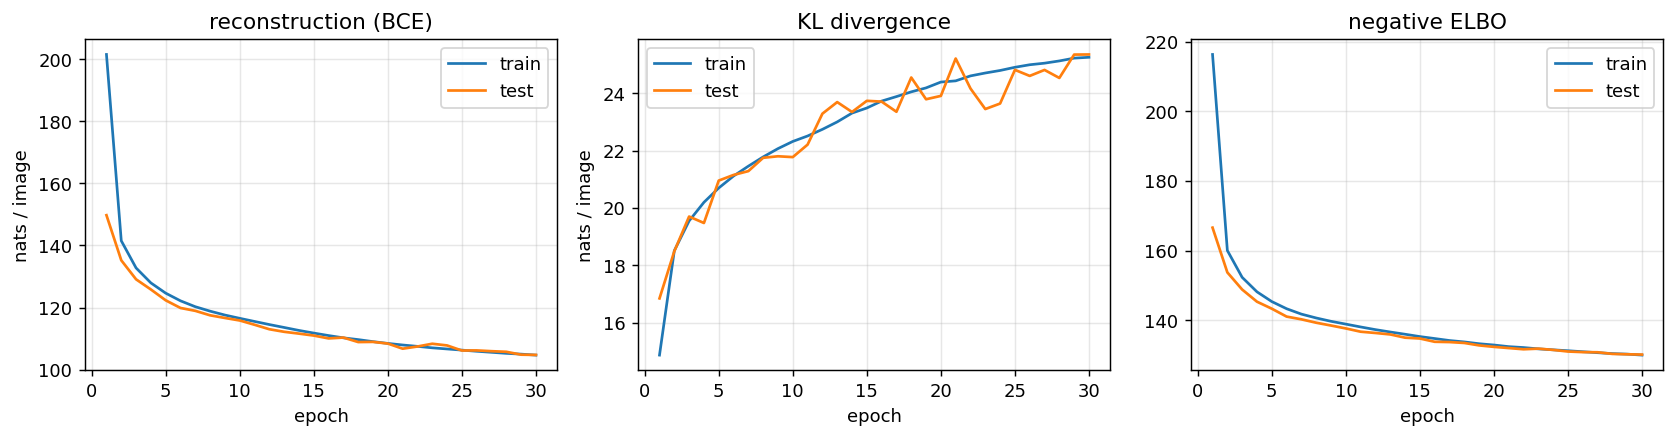

PosixPath('/kaggle/working/results/vae_loss_terms.png')

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
ep = np.arange(1, VAE_EPOCHS + 1)
for ax, key, title in [(axes[0], "rec", "reconstruction (BCE)"), (axes[1], "kl", "KL divergence")]:
    ax.plot(ep, vae_hist[f"train_{key}"], label="train")
    ax.plot(ep, vae_hist[f"test_{key}"], label="test")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("nats / image"); ax.grid(alpha=0.3); ax.legend()
axes[2].plot(ep, np.add(vae_hist["train_rec"], vae_hist["train_kl"]), label="train")
axes[2].plot(ep, np.add(vae_hist["test_rec"], vae_hist["test_kl"]), label="test")
axes[2].set_title("negative ELBO"); axes[2].set_xlabel("epoch"); axes[2].grid(alpha=0.3); axes[2].legend()
fig.tight_layout()
savefig(fig, "vae_loss_terms.png", width=850)

### 5.5 Test negative ELBO

The negative ELBO on the test images, estimated with one posterior sample per image and averaged over five passes.

In [29]:
torch.manual_seed(SEED)
runs = [vae_epoch(vae, te_gpu) for _ in range(5)]
test_rec = float(np.mean([r[0] for r in runs])); test_kl = float(np.mean([r[1] for r in runs]))
REPORT["vae_test"] = dict(rec=test_rec, kl=test_kl, nelbo=test_rec + test_kl)
print(f"test negative ELBO = {test_rec + test_kl:.2f} = reconstruction {test_rec:.2f} + KL {test_kl:.2f} nats per image")

test negative ELBO = 130.12 = reconstruction 104.76 + KL 25.35 nats per image


### 5.6 B.4 (a) Reconstructions

Sixteen test images (rows 1 and 3) and their reconstructions from the posterior mean (rows 2 and 4).

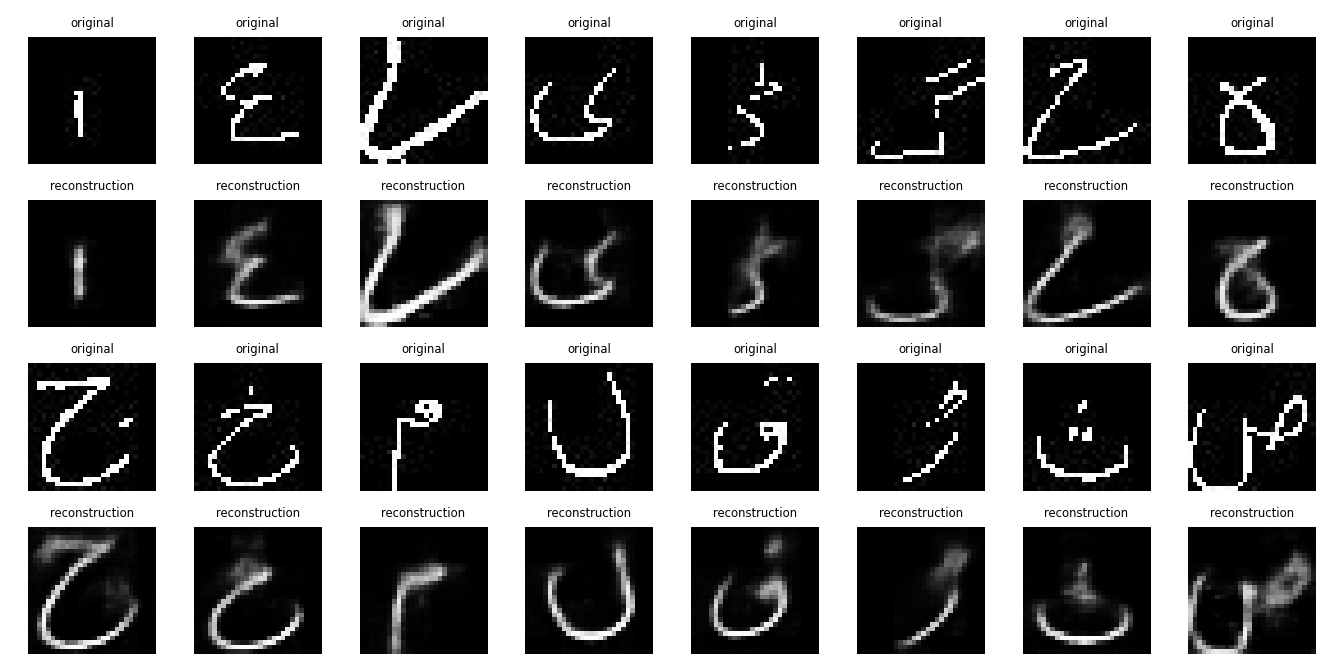

In [30]:
vae.eval()
rec_idx = [int(torch.nonzero(l_te == c)[0]) for c in range(0, len(uhat_names), max(1, len(uhat_names) // 16))][:16]
x = c_te[rec_idx].to(DEVICE)
with torch.no_grad():
    mu, _ = vae.encode(x)
    x_rec = torch.sigmoid(vae.decode(mu))
grid = torch.cat([x[:8], x_rec[:8], x[8:16], x_rec[8:16]])
titles = (["original"] * 8 + ["reconstruction"] * 8) * 2
save_grid(grid, RESULTS / "vae_reconstructions.png", nrow=8, titles=titles)
show(RESULTS / "vae_reconstructions.png", width=600)

### 5.7 B.4 (b) Samples from the prior

Sixty-four latent vectors drawn from $\mathcal N(0, I)$ and decoded; the Bernoulli means are shown.

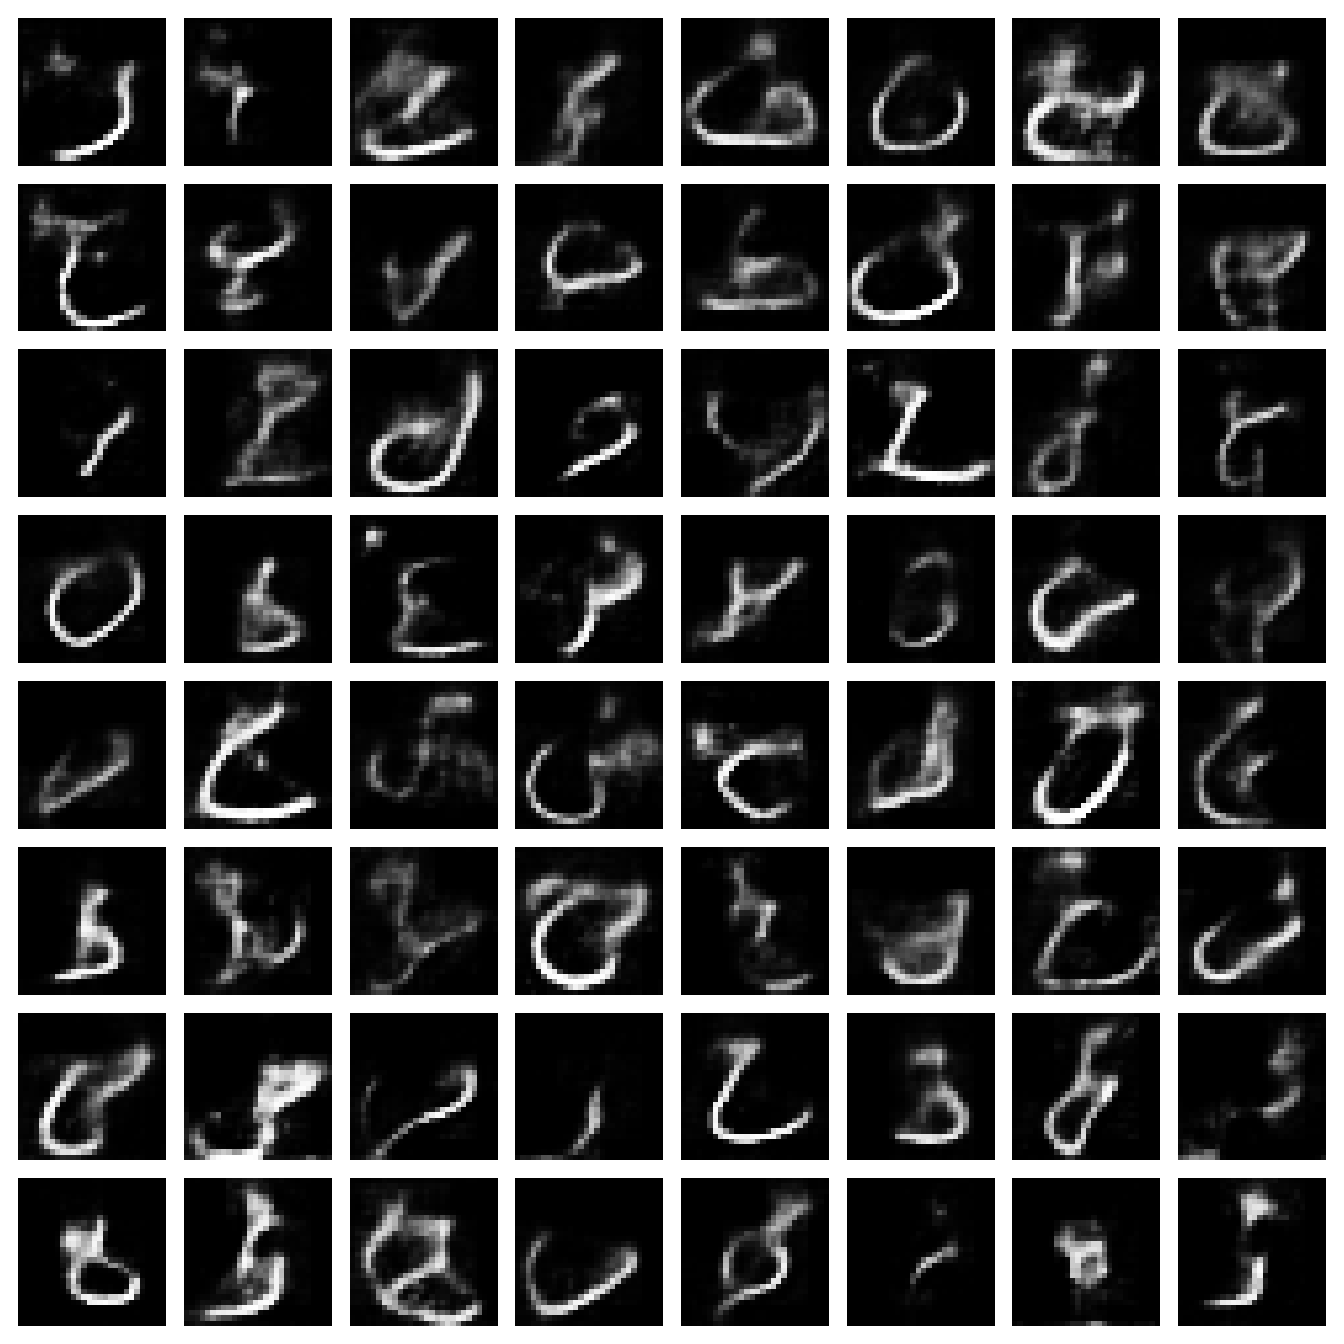

In [31]:
torch.manual_seed(SEED)
vae_samples = vae.sample(64, DEVICE)
save_grid(vae_samples, RESULTS / "vae_samples.png", nrow=8)
show(RESULTS / "vae_samples.png", width=500)

### 5.8 B.4 (c) Interpolation

The posterior means $\mu$ of two test images of different characters are joined by a straight line, and ten equally spaced points on the line (end points included) are decoded. The first row is the required interpolation; three further pairs are shown for comparison.

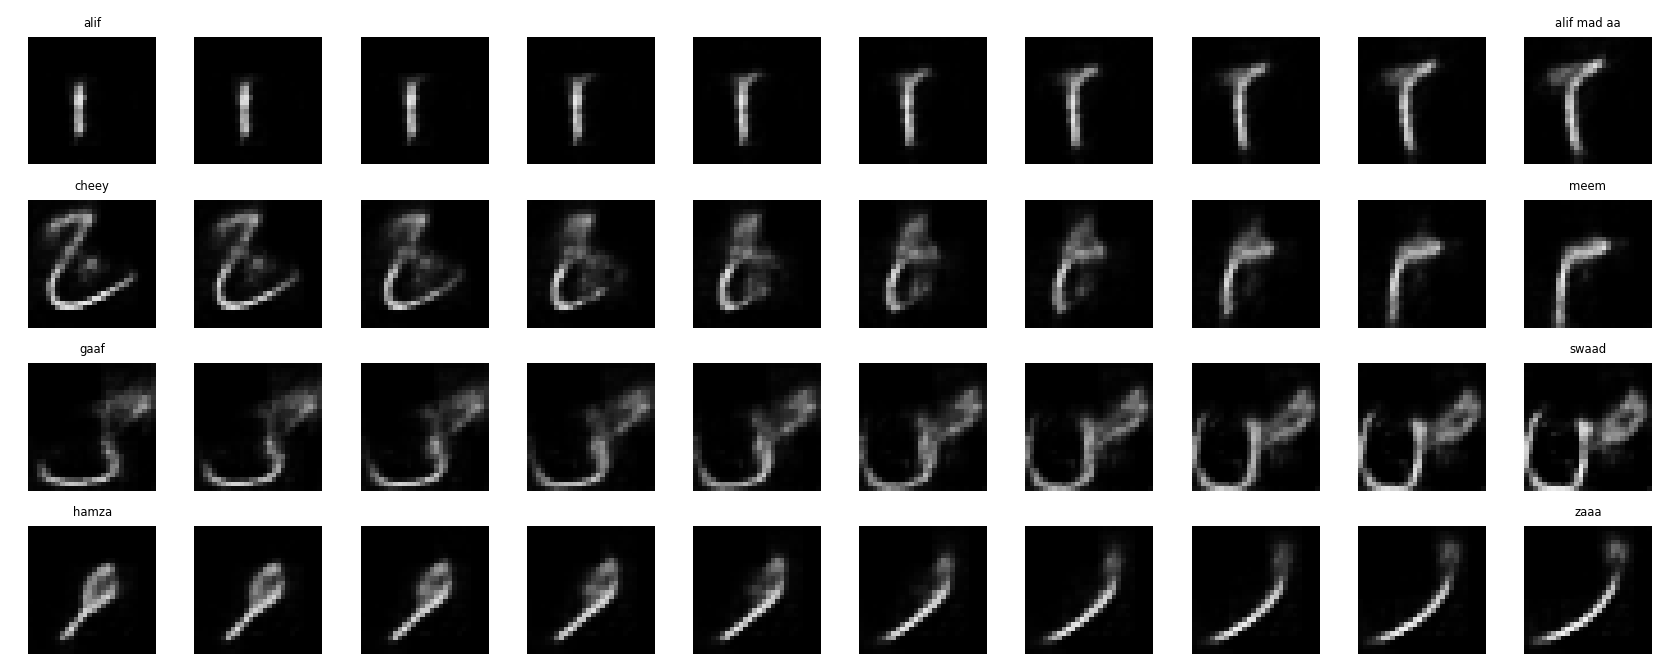

In [32]:
interp_pairs = [(0, 1), (5, 20), (10, 30), (15, 35)]
interp_pairs = [(a % len(uhat_names), b % len(uhat_names)) for a, b in interp_pairs]
rows, titles = [], []
for a, b in interp_pairs:
    xa = c_te[l_te == a][:1].to(DEVICE); xb = c_te[l_te == b][:1].to(DEVICE)
    rows.append(vae.interpolate(xa, xb, steps=10))
    titles += [uhat_names[a]] + [""] * 8 + [uhat_names[b]]
save_grid(torch.cat(rows), RESULTS / "vae_interpolation.png", nrow=10, titles=titles)
show(RESULTS / "vae_interpolation.png", width=750)
del tr_gpu, te_gpu

## 6. Part C – Denoising diffusion: writing a requested character

A class-conditional DDPM is trained on the 40 UHaT character classes with pixels rescaled to [−1, 1]. The requested character is passed to the network as its class label. The noise-prediction network is `diffusers.UNet2DModel`, built with exactly the constructor given in the assignment and randomly initialised; the noise schedule, the forward process, the $L_{\text{simple}}$ training loop and the sampling loop are implemented below. Time steps are indexed $t = 1,\dots,T$ as in the lecture; the arrays of the schedule are stored 0-based and accessed at position $t-1$.

**C.1 Noise schedule.** $T = 1000$, $\beta_t$ linear from $10^{-4}$ to $0.02$, $\alpha_t = 1-\beta_t$, $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$.

**C.2 Forward process.** $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, $\epsilon\sim\mathcal N(0,I)$.

**C.3 Training (Algorithm 1).** Sample $x_0$ with its label $y$, $t \sim \mathrm{Uniform}\{1,\dots,T\}$ and $\epsilon$, and minimise $L_{\text{simple}} = \lVert \epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon,\ t,\ y)\rVert^2$.

**C.4 Sampling (Algorithm 2).** Starting from $x_T \sim \mathcal N(0, I)$, for $t = T,\dots,1$:
$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t, t, y)\right) + \sigma_t z,\qquad \sigma_t^2 = \beta_t,\ z\sim\mathcal N(0,I),$$
with $z = 0$ at the last step; the result is clipped to [−1, 1].

In addition to the specification, an exponential moving average (EMA, decay 0.999) of the network weights is kept during training and used for sampling, and gradients are clipped at norm 1.0, both as in the original DDPM implementation. Neither changes the objective or the sampler.

### 6.1 Schedule, forward process, network and sampler

In [33]:
%%writefile part_c_diffusion/ddpm.py
"""DDPM: linear noise schedule, closed-form forward process, class-conditional U-Net and sampler.
Time steps are 1-based (t = 1..T); schedule arrays are stored 0-based and read at t - 1."""
import copy
import torch
from diffusers import UNet2DModel


class LinearNoiseSchedule:
    def __init__(self, T=1000, beta_start=1e-4, beta_end=0.02, device="cpu"):
        self.T = T
        betas = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
        alphas = 1.0 - betas
        alpha_bars = torch.cumprod(alphas, dim=0)
        to = lambda v: v.float().to(device)
        self.betas, self.alphas, self.alpha_bars = to(betas), to(alphas), to(alpha_bars)
        self.sqrt_alpha_bars = to(alpha_bars.sqrt())
        self.sqrt_one_minus_alpha_bars = to((1 - alpha_bars).sqrt())
        self.sigmas = to(betas.sqrt())

    def alpha_bar(self, t):
        return self.alpha_bars[t - 1]

    def q_sample(self, x0, t, noise):
        """x_t = sqrt(abar_t) x0 + sqrt(1 - abar_t) eps for a (N,) tensor of steps t in 1..T (t = 0 returns x0)."""
        i = (t - 1).clamp(min=0)
        a = torch.where(t > 0, self.sqrt_alpha_bars[i], torch.ones_like(self.sqrt_alpha_bars[i])).view(-1, 1, 1, 1)
        b = torch.where(t > 0, self.sqrt_one_minus_alpha_bars[i], torch.zeros_like(a.view(-1))).view(-1, 1, 1, 1)
        return a * x0 + b * noise


def build_unet():
    """Exactly the constructor given in the assignment (random initialisation)."""
    return UNet2DModel(
        sample_size=28, in_channels=1, out_channels=1, layers_per_block=2,
        block_out_channels=(32, 64, 128),
        down_block_types=("DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
        up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D"),
        num_class_embeds=40)


class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for e, p in zip(self.model.parameters(), model.parameters()):
            e.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
        for e, b in zip(self.model.buffers(), model.buffers()):
            e.copy_(b)


@torch.no_grad()
def ddpm_sample(model, sched, labels, generator=None, record_steps=(), shape=(1, 28, 28)):
    """DDPM Algorithm 2. Returns x_0 clipped to [-1, 1] and {t: x_t} for the requested t (0 = output)."""
    device = labels.device
    n = len(labels)
    x = torch.randn((n, *shape), generator=generator, device=device)
    trajectory = {}
    for t in range(sched.T, 0, -1):
        if t in record_steps:
            trajectory[t] = x.clone()
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt, class_labels=labels).sample.float()
        i = t - 1
        x = (x - (1 - sched.alphas[i]) / sched.sqrt_one_minus_alpha_bars[i] * eps) / sched.alphas[i].sqrt()
        if t > 1:
            x = x + sched.sigmas[i] * torch.randn(x.shape, generator=generator, device=device)
    x = x.clamp(-1, 1)
    if 0 in record_steps:
        trajectory[0] = x.clone()
    return x, trajectory

Writing part_c_diffusion/ddpm.py


In [34]:
import part_c_diffusion.ddpm as _mc
importlib.reload(_mc)
from part_c_diffusion.ddpm import LinearNoiseSchedule, build_unet, EMA, ddpm_sample

NUM_CLASSES = len(uhat_names)
assert NUM_CLASSES == 40, "the U-Net constructor fixes num_class_embeds=40"
sched = LinearNoiseSchedule(T=1000, device=DEVICE)
seed_everything(SEED)
unet = build_unet().to(DEVICE)
print(f"U-Net parameters: {count_params(unet):,}")

U-Net parameters: 4,028,353


### 6.2 Correctness checks

alpha_bar_T = 4.036e-05 (expected about 4e-5); sqrt(alpha_bar_T) = 0.0064
x_999 over 512 images: mean -0.0064, std 0.9990 (N(0,1) expected); correlation with x_0: 0.0048
U-Net output shape (4, 1, 28, 28) for input (4, 1, 28, 28)


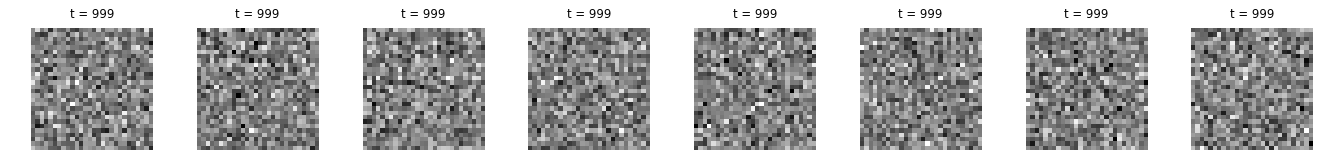

In [35]:
checks_c = []
abar_T = sched.alpha_bar(sched.T).item()
checks_c.append(f"alpha_bar_T = {abar_T:.3e} (expected about 4e-5); sqrt(alpha_bar_T) = {abar_T ** 0.5:.4f}")
assert 2e-5 < abar_T < 8e-5

x0 = (c_tr[:512] * 2 - 1).to(DEVICE)
g = torch.Generator(device=DEVICE).manual_seed(SEED)
noise = torch.randn(x0.shape, generator=g, device=DEVICE)
x999 = sched.q_sample(x0, torch.full((len(x0),), 999, device=DEVICE), noise)
save_grid((x999[:8].clamp(-3, 3) + 3) / 6, RESULTS / "ddpm_check_t999.png", nrow=8, titles=["t = 999"] * 8)
corr = torch.corrcoef(torch.stack([x999.flatten(), x0.flatten()]))[0, 1].item()
checks_c.append(f"x_999 over 512 images: mean {x999.mean():.4f}, std {x999.std():.4f} "
                f"(N(0,1) expected); correlation with x_0: {corr:.4f}")
assert abs(x999.mean()) < 0.05 and abs(x999.std() - 1) < 0.05

with torch.no_grad():
    out = unet(x0[:4], torch.tensor([1, 10, 500, 1000], device=DEVICE),
               class_labels=torch.tensor([0, 1, 2, 39], device=DEVICE)).sample
checks_c.append(f"U-Net output shape {tuple(out.shape)} for input {tuple(x0[:4].shape)}")
print("\n".join(checks_c))
REPORT["checks_c"] = checks_c
show(RESULTS / "ddpm_check_t999.png", width=600)

### 6.3 C.2 Forward noising of one training image

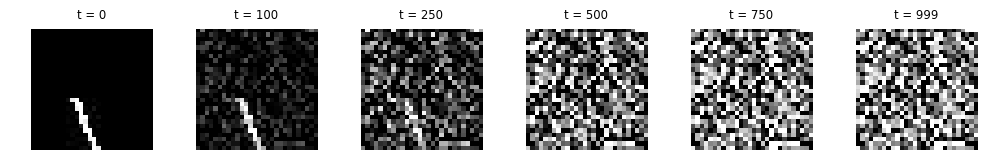

In [36]:
steps = [0, 100, 250, 500, 750, 999]
x0_one = (c_tr[:1] * 2 - 1).to(DEVICE)
eps_one = torch.randn(x0_one.shape, generator=torch.Generator(device=DEVICE).manual_seed(1), device=DEVICE)
frames = [sched.q_sample(x0_one, torch.tensor([t], device=DEVICE), eps_one) for t in steps]
save_grid((torch.cat(frames) + 1) / 2, RESULTS / "ddpm_forward_noising.png", nrow=len(steps),
          titles=[f"t = {t}" for t in steps])
show(RESULTS / "ddpm_forward_noising.png", width=600)

### 6.4 C.3 Training with $L_{\text{simple}}$

Adam with learning rate 2 × 10⁻⁴, batch size 128, 40 epochs; the loss is logged per epoch. Mixed precision is used on the GPU.

In [37]:
x_all = (c_tr * 2 - 1).to(DEVICE)
y_all = l_tr.to(DEVICE)
if SMOKE_TEST:
    x_all, y_all = x_all[:512], y_all[:512]

seed_everything(SEED)
unet = build_unet().to(DEVICE)
ema = EMA(unet, decay=0.999)
opt = torch.optim.Adam(unet.parameters(), lr=2e-4)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
BS = 128

ddpm_hist = []
sync(); t0 = time.time()
for ep in range(1, DDPM_EPOCHS + 1):
    unet.train()
    perm = torch.randperm(len(x_all), device=DEVICE)
    total, n = 0.0, 0
    for i in range(0, len(x_all), BS):
        idx = perm[i:i + BS]
        x0, y = x_all[idx], y_all[idx]
        t = torch.randint(1, sched.T + 1, (len(x0),), device=DEVICE)          # t ~ Uniform{1, ..., T}
        eps = torch.randn_like(x0)
        xt = sched.q_sample(x0, t, eps)
        with autocast():
            eps_hat = unet(xt, t, class_labels=y).sample
        loss = F.mse_loss(eps_hat.float(), eps)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        ema.update(unet)
        total += loss.item() * len(x0); n += len(x0)
    ddpm_hist.append(total / n)
    if ep == 1 or ep % 5 == 0 or ep == DDPM_EPOCHS:
        print(f"epoch {ep:3d} | L_simple {ddpm_hist[-1]:.5f} | {(time.time() - t0) / 60:.1f} min")
sync(); ddpm_time = time.time() - t0

REPORT["ddpm_train"] = dict(params=count_params(unet), final_loss=ddpm_hist[-1], time_min=ddpm_time / 60)
json.dump(ddpm_hist, open(RESULTS / "ddpm_loss_history.json", "w"))
torch.save({"unet_ema": ema.model.state_dict(), "unet": unet.state_dict(), "class_names": uhat_names},
           WEIGHTS / "ddpm_uhat.pt")
del x_all, y_all

epoch   1 | L_simple 0.11015 | 0.6 min
epoch   5 | L_simple 0.03271 | 2.6 min
epoch  10 | L_simple 0.02774 | 5.3 min
epoch  15 | L_simple 0.02593 | 7.9 min
epoch  20 | L_simple 0.02461 | 10.5 min
epoch  25 | L_simple 0.02394 | 13.1 min
epoch  30 | L_simple 0.02338 | 15.7 min
epoch  35 | L_simple 0.02300 | 18.3 min
epoch  40 | L_simple 0.02271 | 21.0 min


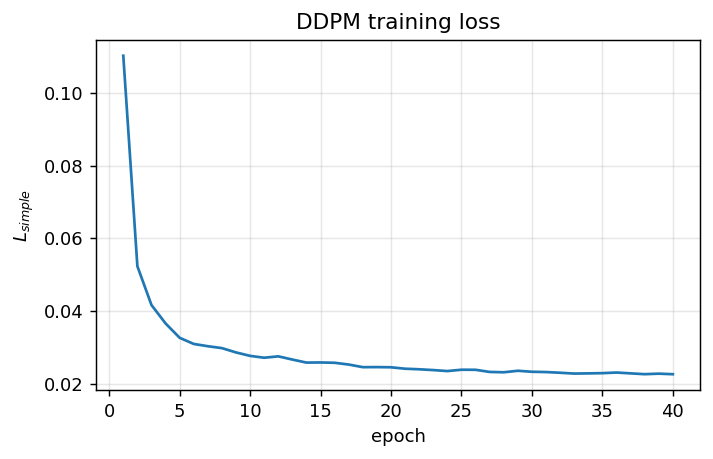

PosixPath('/kaggle/working/results/ddpm_training_loss.png')

In [38]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(ddpm_hist) + 1), ddpm_hist)
ax.set_xlabel("epoch"); ax.set_ylabel(r"$L_{simple}$"); ax.set_title("DDPM training loss"); ax.grid(alpha=0.3)
savefig(fig, "ddpm_training_loss.png", width=500)

### 6.5 C.4 and C.5 Samples: 40 characters × 8

320 samples in 124 s (0.39 s per image, 1000 steps)


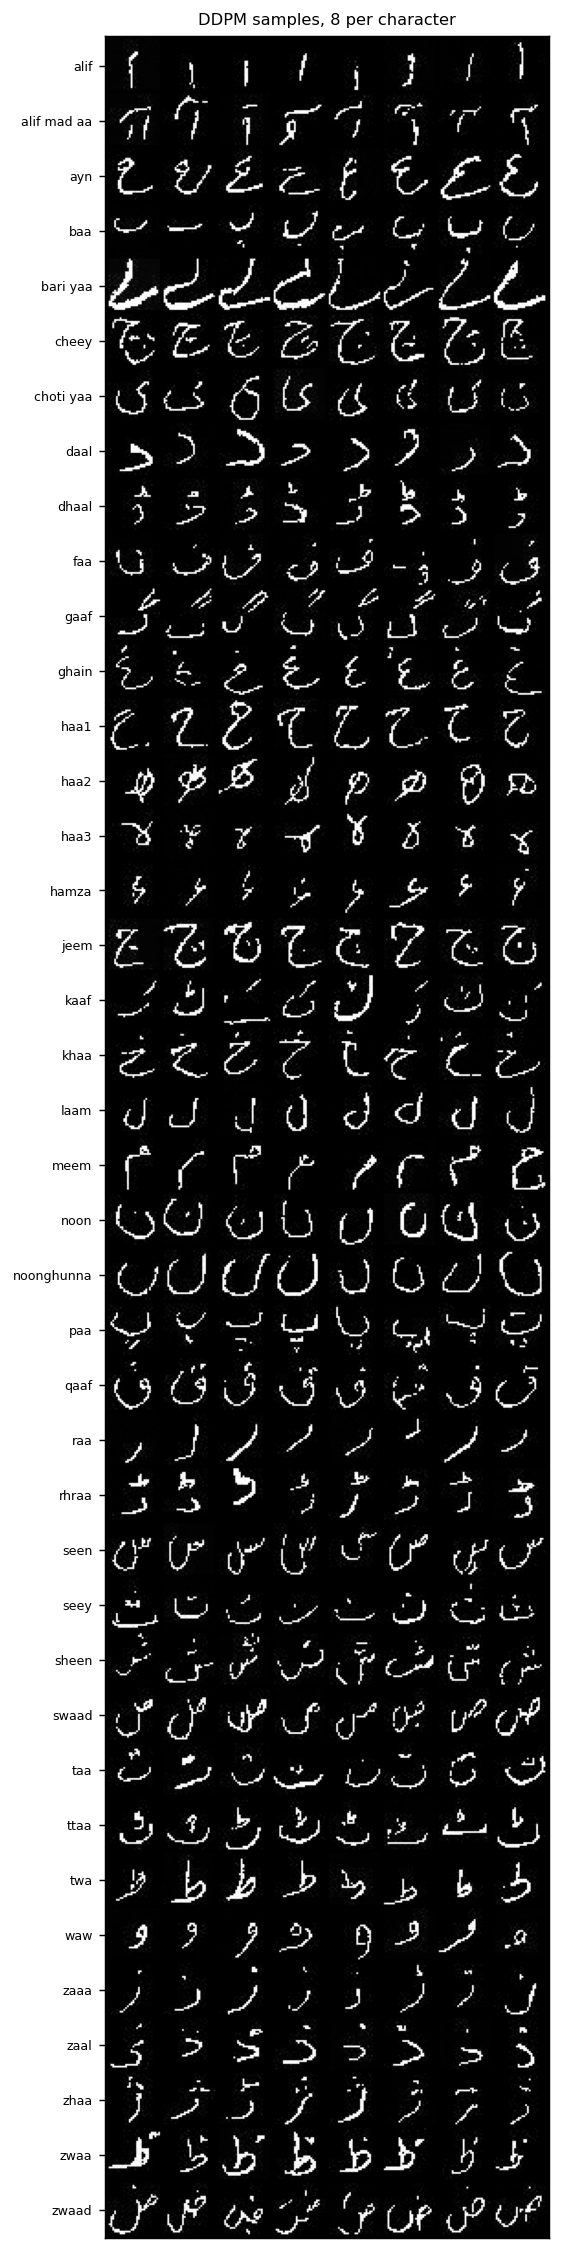

In [39]:
def tile(images, nrow, pad=2, value=0.0):
    """(N, 1, H, W) in [0, 1] -> one (rows*H, nrow*W) array with padding."""
    images = images.detach().cpu().clamp(0, 1)
    n, _, h, w = images.shape
    rows = (n + nrow - 1) // nrow
    canvas = torch.full((rows * (h + pad) + pad, nrow * (w + pad) + pad), value)
    for k in range(n):
        r, c = divmod(k, nrow)
        canvas[pad + r * (h + pad): pad + r * (h + pad) + h, pad + c * (w + pad): pad + c * (w + pad) + w] = images[k, 0]
    return canvas.numpy()


PER_CLASS = 2 if SMOKE_TEST else 8
sampler = ema.model.eval()
labels = torch.arange(NUM_CLASSES, device=DEVICE).repeat_interleave(PER_CLASS)
gen = torch.Generator(device=DEVICE).manual_seed(SEED)
chunks = []
sync(); t0 = time.time()
for i in range(0, len(labels), 160):
    with autocast():
        xs, _ = ddpm_sample(sampler, sched, labels[i:i + 160], generator=gen)
    chunks.append(xs.float())
sync(); sample_time = time.time() - t0
ddpm_samples = (torch.cat(chunks) + 1) / 2
REPORT["ddpm_sampling"] = dict(n=len(labels), seconds=sample_time)
print(f"{len(labels)} samples in {sample_time:.0f} s ({sample_time / len(labels):.2f} s per image, 1000 steps)")

canvas = tile(ddpm_samples, nrow=PER_CLASS)
fig, ax = plt.subplots(figsize=(PER_CLASS * 0.55 + 1.5, NUM_CLASSES * 0.55))
ax.imshow(canvas, cmap="gray", vmin=0, vmax=1)
ax.set_yticks([2 + 30 * i + 14 for i in range(NUM_CLASSES)]); ax.set_yticklabels(uhat_names, fontsize=7)
ax.set_xticks([]); ax.set_title(f"DDPM samples, {PER_CLASS} per character", fontsize=9)
savefig(fig, "ddpm_samples_40x8.png", width=420)
torch.save(ddpm_samples.cpu(), RESULTS / "ddpm_samples.pt")

### 6.6 C.5 Denoising of one sample

character: alif


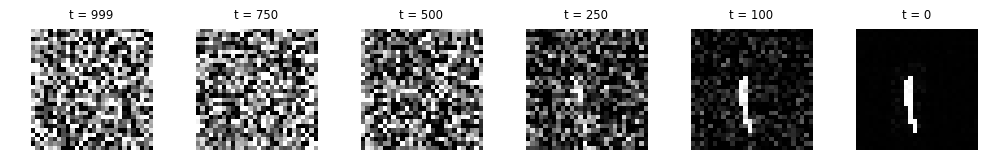

In [40]:
record = [999, 750, 500, 250, 100, 0]
gen = torch.Generator(device=DEVICE).manual_seed(SEED + 7)
with autocast():
    _, traj = ddpm_sample(sampler, sched, torch.tensor([0], device=DEVICE), generator=gen, record_steps=record)
frames = [traj[t].float().clamp(-1, 1) for t in record]
save_grid((torch.cat(frames) + 1) / 2, RESULTS / "ddpm_denoising.png", nrow=len(frames),
          titles=[f"t = {t}" for t in record])
print("character:", uhat_names[0])
show(RESULTS / "ddpm_denoising.png", width=600)

### 6.7 Blind recognisability test

One new sample of each of the 40 characters is generated and the order is shuffled with a fixed seed. The numbered sheet `results/diffusion_blind_test.png` is given to both members, who independently record the character they read in each image in `results/human_eval.csv`. The answer key is kept in a separate file and is only merged in Section 8.

added 40 'diffusion' rows to human_eval.csv


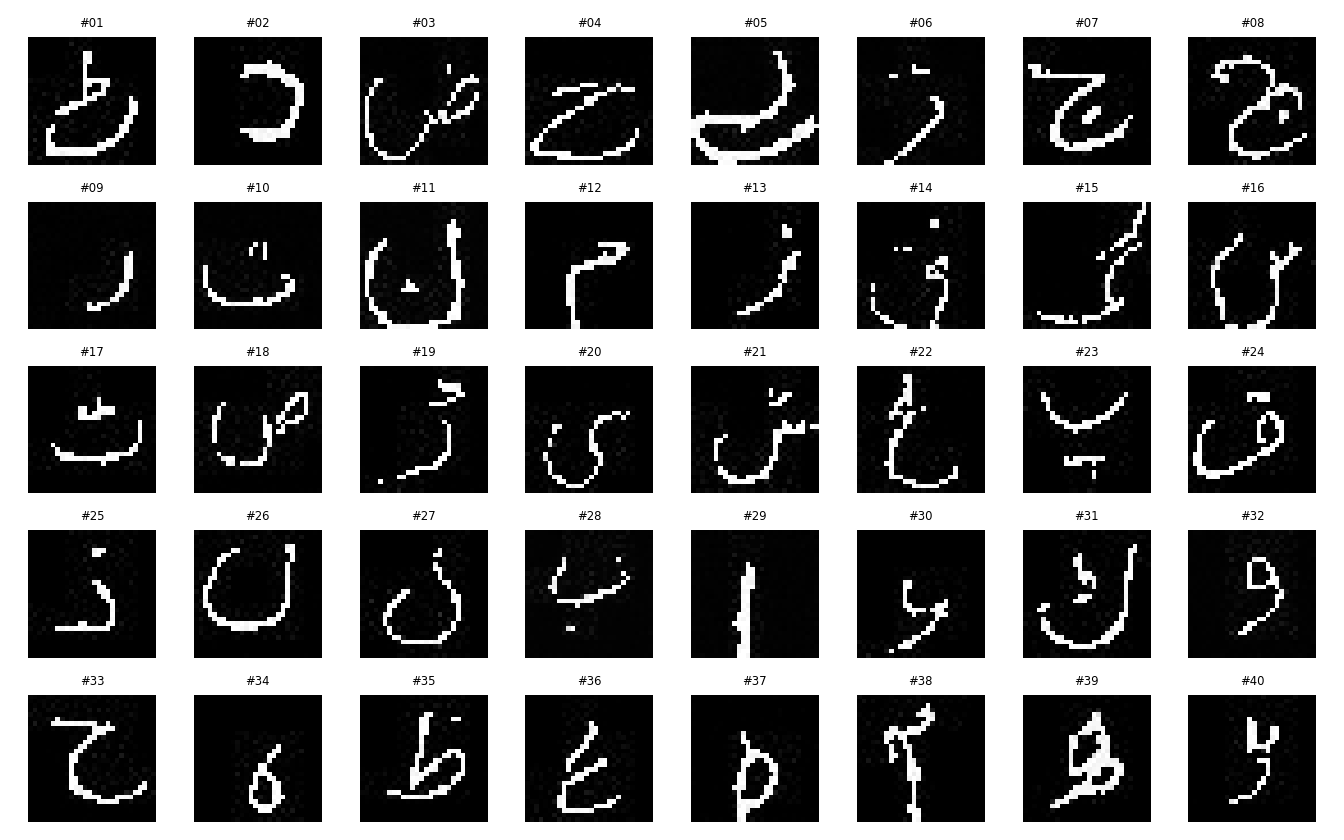

Character names that may be used in the sheet: alif, alif mad aa, ayn, baa, bari yaa, cheey, choti yaa, daal, dhaal, faa, gaaf, ghain, haa1, haa2, haa3, hamza, jeem, kaaf, khaa, laam, meem, noon, noonghunna, paa, qaaf, raa, rhraa, seen, seey, sheen, swaad, taa, ttaa, twa, waw, zaaa, zaal, zhaa, zwaa, zwaad


In [41]:
HUMAN_CSV = RESULTS / "human_eval.csv"
HUMAN_FIELDS = ["task", "item", "true_label", "member1", "member2",
                "member1_supported", "member2_supported", "member1_correct", "member2_correct"]

def read_human_sheet():
    if not HUMAN_CSV.exists():
        return []
    with open(HUMAN_CSV, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

def write_human_sheet(rows):
    with open(HUMAN_CSV, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=HUMAN_FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: r.get(k, "") for k in HUMAN_FIELDS})

def add_human_rows(task, items):
    """Adds empty rows for `task` only if none exist yet, so filled-in answers are never overwritten."""
    rows = read_human_sheet()
    if any(r["task"] == task for r in rows):
        print(f"human_eval.csv already contains '{task}' rows; left unchanged")
        return
    rows += [{"task": task, "item": str(i)} for i in items]
    write_human_sheet(rows)
    print(f"added {len(items)} '{task}' rows to {HUMAN_CSV.name}")


blind_order = np.random.default_rng(SEED).permutation(NUM_CLASSES)
gen = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
with autocast():
    blind_x, _ = ddpm_sample(sampler, sched, torch.tensor(blind_order, device=DEVICE), generator=gen)
save_grid((blind_x.float() + 1) / 2, RESULTS / "diffusion_blind_test.png", nrow=8,
          titles=[f"#{i + 1:02d}" for i in range(NUM_CLASSES)])
with open(RESULTS / "diffusion_blind_key.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["image", "true_label"])
    for i, c in enumerate(blind_order):
        w.writerow([i + 1, uhat_names[c]])
add_human_rows("diffusion", range(1, NUM_CLASSES + 1))
show(RESULTS / "diffusion_blind_test.png", width=600)
print("Character names that may be used in the sheet:", ", ".join(uhat_names))

## 7. Part D – Retrieval-augmented generation for biomedical questions

> **For educational use only. Not medical advice.**

| Role | Model |
|---|---|
| Retriever (questions and chunks) | `sentence-transformers/all-MiniLM-L6-v2`, 384 dimensions, loaded with `AutoModel` |
| Generator | `Qwen/Qwen2.5-1.5B-Instruct`, float16 on the GPU, loaded with `AutoModelForCausalLM` |

### 7.1 Data

In [42]:
corpus = load_corpus()
if SMOKE_TEST:
    corpus = dict(list(corpus.items())[:2000])
test_qs = load_questions("test", corpus)
n_rel = [len(q["relevant_ids"]) for q in test_qs]
print(f"abstracts: {len(corpus):,} | test questions: {len(test_qs)} | "
      f"relevant abstracts per question: mean {np.mean(n_rel):.2f}, median {np.median(n_rel):.0f}, max {max(n_rel)}")
print("example question:", test_qs[0]["question"])
REPORT["bioasq"] = dict(abstracts=len(corpus), questions=len(test_qs), mean_relevant=float(np.mean(n_rel)))

abstracts: 40,181 | test questions: 707 | relevant abstracts per question: mean 8.66, median 6, max 77
example question: Is capmatinib effective for glioblastoma?


### 7.2 Retrieval and generation module

`part_d_rag/rag.py` contains the chunker, the mean-pooling encoder, the dense index with abstract-level max-pooling of chunk scores, the retrieval metrics, the prompt and the answer parsing. The index is a plain matrix of L2-normalised embeddings; search is a single matrix multiplication followed by `topk`.

In [43]:
%%writefile part_d_rag/rag.py
"""Chunking, MiniLM encoder with mean pooling, dense index, retrieval metrics and prompting."""
import re
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel

MEDICAL_NOTICE = "For educational use only. Not medical advice."
IDK_SENTENCE = "I don't know based on the provided passages."


# ---------------------------------------------------------------- chunking
def chunk_words(text, size=150, overlap=30):
    """Windows of at most `size` words; consecutive windows share `overlap` words."""
    words = text.split()
    if not words:
        return []
    step = size - overlap
    chunks, start = [], 0
    while True:
        chunks.append(" ".join(words[start:start + size]))
        if start + size >= len(words):
            break
        start += step
    return chunks


def build_chunks(corpus, size=150, overlap=30):
    texts, pids = [], []
    for pid, text in corpus.items():
        for c in chunk_words(text, size, overlap):
            texts.append(c)
            pids.append(pid)
    return texts, pids


# ---------------------------------------------------------------- encoder
def mean_pool(last_hidden, attention_mask):
    """Average of the token states over real tokens only (padding excluded)."""
    m = attention_mask.unsqueeze(-1).to(last_hidden.dtype)
    return (last_hidden * m).sum(dim=1) / m.sum(dim=1).clamp(min=1e-9)


class MeanPoolEncoder:
    def __init__(self, name, device, max_length=256):
        self.device = device
        self.max_length = max_length
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModel.from_pretrained(name).to(device).eval()
        if device.type == "cuda":
            self.model.half()
        self.dim = self.model.config.hidden_size

    @torch.no_grad()
    def encode(self, texts, batch_size=256):
        order = sorted(range(len(texts)), key=lambda i: len(texts[i]))   # length bucketing
        out = torch.empty(len(texts), self.dim)
        for s in range(0, len(texts), batch_size):
            idx = order[s:s + batch_size]
            enc = self.tok([texts[i] for i in idx], padding=True, truncation=True,
                           max_length=self.max_length, return_tensors="pt").to(self.device)
            h = self.model(**enc).last_hidden_state.float()
            out[idx] = F.normalize(mean_pool(h, enc["attention_mask"].float()), dim=-1).cpu()
        return out

    def token_lengths(self, texts, batch_size=1024):
        lengths = []
        for s in range(0, len(texts), batch_size):
            lengths += [len(ids) for ids in self.tok(texts[s:s + batch_size])["input_ids"]]
        return lengths


# ---------------------------------------------------------------- index and search
class DenseIndex:
    def __init__(self, embeddings, chunk_pids, device):
        self.device = device
        self.emb = embeddings.to(device)
        self.chunk_pids = list(chunk_pids)
        self.abstract_ids = sorted(set(self.chunk_pids))
        col = {pid: j for j, pid in enumerate(self.abstract_ids)}
        self.chunk_col = torch.tensor([col[p] for p in self.chunk_pids], device=device)

    def chunk_scores(self, q):
        """Cosine similarity of every question with every chunk: one matrix multiplication."""
        return q.to(self.device, self.emb.dtype) @ self.emb.T

    @torch.no_grad()
    def search_abstracts(self, q, k=10, batch_size=128):
        """An abstract's score is the maximum score of its chunks. Returns top-k ids and scores."""
        ids, scores = [], []
        for s in range(0, len(q), batch_size):
            cs = self.chunk_scores(q[s:s + batch_size]).float()
            ab = torch.full((len(cs), len(self.abstract_ids)), float("-inf"), device=self.device)
            ab.scatter_reduce_(1, self.chunk_col.unsqueeze(0).expand(len(cs), -1), cs,
                               reduce="amax", include_self=True)
            top = ab.topk(min(k, ab.shape[1]), dim=1)
            ids += [[self.abstract_ids[j] for j in row] for row in top.indices.tolist()]
            scores += top.values.tolist()
        return ids, scores

    @torch.no_grad()
    def search_chunks(self, q, k=5):
        top = self.chunk_scores(q).float().topk(k, dim=1)
        return top.indices.tolist(), top.values.tolist()


# ---------------------------------------------------------------- metrics
def hit_at_k(ranked, relevant, k):
    return float(len(set(ranked[:k]) & set(relevant)) >= 1)


def recall_at_k(ranked, relevant, k):
    return len(set(ranked[:k]) & set(relevant)) / min(k, len(set(relevant)))


def mrr_at_k(ranked, relevant, k=10):
    rel = set(relevant)
    for rank, pid in enumerate(ranked[:k], start=1):
        if pid in rel:
            return 1.0 / rank
    return 0.0


def evaluate_retrieval(rankings, relevants, ks=(1, 5, 10)):
    res = {}
    for k in ks:
        res[f"Hit@{k}"] = sum(hit_at_k(r, g, k) for r, g in zip(rankings, relevants)) / len(rankings)
        res[f"Recall@{k}"] = sum(recall_at_k(r, g, k) for r, g in zip(rankings, relevants)) / len(rankings)
    res["MRR@10"] = sum(mrr_at_k(r, g, 10) for r, g in zip(rankings, relevants)) / len(rankings)
    return res


# ---------------------------------------------------------------- prompting
SYSTEM_PROMPT = (
    "You are an assistant that answers biomedical research questions for educational purposes. "
    "Answer using only the information in the numbered passages provided by the user. "
    "Cite the passages that support each statement with their numbers in square brackets, for example [2] or [1][3]. "
    "Do not use outside knowledge. If the passages do not contain the answer, reply exactly: "
    + IDK_SENTENCE)


def build_messages(question, passages):
    context = "\n\n".join(f"[{i}] {p}" for i, p in enumerate(passages, start=1))
    user = f"Passages:\n{context}\n\nQuestion: {question}\n\nAnswer concisely, citing passage numbers."
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]


_CITE = re.compile(r"\[(\s*\d+\s*(?:[,;\-–]\s*\d+\s*)*)\]")


def parse_citations(text, n_passages=5):
    """Set of passage numbers cited as [2], [1, 3], [1-3] or [1][4]."""
    cited = set()
    for group in _CITE.findall(text):
        for part in re.split(r"[,;]", group):
            part = part.strip()
            if re.fullmatch(r"\d+\s*[\-–]\s*\d+", part):
                a, b = map(int, re.split(r"[\-–]", part))
                cited.update(range(min(a, b), max(a, b) + 1))
            elif part.isdigit():
                cited.add(int(part))
    return {c for c in cited if 1 <= c <= n_passages}


_IDK = re.compile(r"i do(?:n['’]t| not) know|(?:passages|context|information provided) "
                  r"(?:do(?:es)? not|don['’]t) (?:contain|provide|mention|include)", re.I)


def is_idk(text):
    return bool(_IDK.search(text))

Writing part_d_rag/rag.py


In [44]:
import part_d_rag.rag as _md
importlib.reload(_md)
from part_d_rag.rag import (chunk_words, build_chunks, mean_pool, MeanPoolEncoder, DenseIndex,
                            hit_at_k, recall_at_k, mrr_at_k, evaluate_retrieval, build_messages,
                            parse_citations, is_idk, MEDICAL_NOTICE, IDK_SENTENCE)

### 7.3 D.1 Chunking

Every abstract is split into windows of at most 150 words with a stride of 120 words, so consecutive chunks share 30 words. Each chunk keeps the id of its abstract.

In [45]:
chunk_texts, chunk_pids = build_chunks(corpus, size=150, overlap=30)
chunk_words_n = [len(t.split()) for t in chunk_texts]
per_abstract = np.bincount(np.unique(chunk_pids, return_inverse=True)[1])
print(f"chunks: {len(chunk_texts):,} from {len(corpus):,} abstracts "
      f"(mean {per_abstract.mean():.2f} per abstract, max {per_abstract.max()})")
print(f"words per chunk: max {max(chunk_words_n)}, mean {np.mean(chunk_words_n):.1f}")

# overlap check on the first abstract with more than one chunk
pid_multi = next(p for p in corpus if len(corpus[p].split()) > 150)
cs = chunk_words(corpus[pid_multi])
assert cs[0].split()[-30:] == cs[1].split()[:30]
REPORT["bioasq"]["chunks"] = len(chunk_texts)

chunks: 79,332 from 40,181 abstracts (mean 1.97 per abstract, max 35)
words per chunk: max 150, mean 121.3


### 7.4 D.2 Embedding index

Chunks are tokenised with truncation at 256 tokens. The last hidden states are averaged over the real tokens using the attention mask, then L2-normalised. The matrix of chunk embeddings is saved to `weights/rag_index.pt`; questions are encoded with the same function.

In [46]:
encoder = MeanPoolEncoder(RETRIEVER_NAME, DEVICE, max_length=256)
print("retriever embedding dimension:", encoder.dim)

tok_len = np.array(encoder.token_lengths(chunk_texts))
REPORT["bioasq"]["truncated_share"] = float((tok_len > 256).mean())
print(f"tokens per chunk: mean {tok_len.mean():.0f}, max {tok_len.max()}; "
      f"chunks longer than 256 tokens (truncated): {100 * (tok_len > 256).mean():.1f} %")

INDEX_PATH = WEIGHTS / "rag_index.pt"
cached = torch.load(INDEX_PATH) if INDEX_PATH.exists() else None
if cached is not None and cached["pids"] == chunk_pids and cached["model"] == RETRIEVER_NAME:
    chunk_emb = cached["embeddings"]
    print("loaded index from", INDEX_PATH)
else:
    sync(); t0 = time.time()
    chunk_emb = encoder.encode(chunk_texts, batch_size=256)
    sync(); print(f"encoded {len(chunk_texts):,} chunks in {time.time() - t0:.0f} s")
    torch.save({"embeddings": chunk_emb, "pids": chunk_pids, "model": RETRIEVER_NAME}, INDEX_PATH)
    with open(WEIGHTS / "rag_chunks.json", "w") as f:
        json.dump({"texts": chunk_texts, "pids": chunk_pids}, f)
print("index matrix:", tuple(chunk_emb.shape), chunk_emb.dtype)

index = DenseIndex(chunk_emb, chunk_pids, DEVICE)
q_emb = encoder.encode([q["question"] for q in test_qs], batch_size=256)

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

retriever embedding dimension: 384


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (584 > 512). Running this sequence through the model will result in indexing errors


tokens per chunk: mean 198, max 1066; chunks longer than 256 tokens (truncated): 18.3 %
encoded 79,332 chunks in 75 s
index matrix: (79332, 384) torch.float32


### 7.5 Correctness checks

In [47]:
checks_d = []
checks_d.append(f"largest chunk: {max(chunk_words_n)} words (limit 150)")
assert max(chunk_words_n) <= 150

norms = torch.cat([chunk_emb.norm(dim=1), q_emb.norm(dim=1)])
checks_d.append(f"embedding norms (chunks and questions): min {norms.min():.6f}, max {norms.max():.6f}")
assert torch.allclose(norms, torch.ones_like(norms), atol=1e-4)

# mean pooling ignores padding: a text encoded alone and inside a padded batch gives the same vector
alone = encoder.encode([test_qs[0]["question"]])
batched = encoder.encode([test_qs[0]["question"], chunk_texts[int(np.argmax(chunk_words_n))]])[0:1]
checks_d.append(f"padding invariance of mean pooling: cosine(alone, padded batch) = {(alone @ batched.T).item():.5f}")

all_ids = list(corpus.keys())
perfect = []
for q in test_qs:
    rel = set(q["relevant_ids"])
    perfect.append(q["relevant_ids"] + [p for p in all_ids[:50] if p not in rel])
pm = evaluate_retrieval(perfect, [q["relevant_ids"] for q in test_qs])
checks_d.append("perfect retriever: " + ", ".join(f"{k} = {v:.3f}" for k, v in pm.items()))
assert all(abs(v - 1) < 1e-9 for v in pm.values())

print("\n".join(checks_d))
REPORT["checks_d"] = checks_d

largest chunk: 150 words (limit 150)
embedding norms (chunks and questions): min 1.000000, max 1.000000
padding invariance of mean pooling: cosine(alone, padded batch) = 1.00000
perfect retriever: Hit@1 = 1.000, Recall@1 = 1.000, Hit@5 = 1.000, Recall@5 = 1.000, Hit@10 = 1.000, Recall@10 = 1.000, MRR@10 = 1.000


### 7.6 D.3 and D.4 Search and retrieval evaluation

The top-20 abstracts are retrieved for every test question. Hit@k, Recall@k (with denominator $\min(k, |R_q|)$) and MRR@10 are averaged over all test questions.

In [48]:
sync(); t0 = time.time()
rankings, rank_scores = index.search_abstracts(q_emb, k=20)
sync(); search_ms = 1000 * (time.time() - t0) / len(test_qs)
relevants = [q["relevant_ids"] for q in test_qs]

retrieval = evaluate_retrieval(rankings, relevants, ks=(1, 5, 10))
REPORT["retrieval"] = retrieval
print(f"search time: {search_ms:.2f} ms per question over {len(chunk_texts):,} chunks\n")
print(" | ".join(f"{k} {v:.3f}" for k, v in retrieval.items()))

recall_curve = [float(np.mean([recall_at_k(r, g, k) for r, g in zip(rankings, relevants)])) for k in range(1, 21)]
hit_curve = [float(np.mean([hit_at_k(r, g, k) for r, g in zip(rankings, relevants)])) for k in range(1, 21)]
json.dump({"retrieval": retrieval, "recall_curve": recall_curve, "hit_curve": hit_curve},
          open(RESULTS / "rag_retrieval_metrics.json", "w"), indent=2)

search time: 0.08 ms per question over 79,332 chunks

Hit@1 0.622 | Recall@1 0.622 | Hit@5 0.816 | Recall@5 0.587 | Hit@10 0.861 | Recall@10 0.602 | MRR@10 0.706


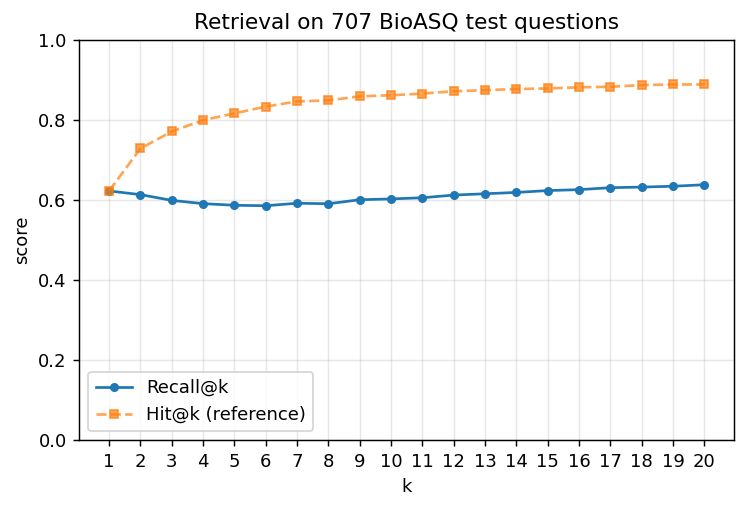

PosixPath('/kaggle/working/results/rag_recall_at_k.png')

In [49]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ks = np.arange(1, 21)
ax.plot(ks, recall_curve, marker="o", ms=4, label="Recall@k")
ax.plot(ks, hit_curve, marker="s", ms=4, ls="--", alpha=0.7, label="Hit@k (reference)")
ax.set_xticks(ks); ax.set_ylim(0, 1); ax.set_xlabel("k"); ax.set_ylabel("score")
ax.set_title(f"Retrieval on {len(test_qs)} BioASQ test questions"); ax.grid(alpha=0.3); ax.legend()
savefig(fig, "rag_recall_at_k.png", width=520)

### 7.7 D.5 Generation

For each question the five highest-scoring chunks (not whole abstracts) are numbered [1]–[5] and inserted into the prompt. The system message instructs the model to answer only from the passages, to cite passage numbers in square brackets, and to reply with a fixed sentence when the passages do not contain the answer. The model's chat template is applied and decoding is greedy with at most 256 new tokens. Prompts are left-padded and generated in batches.

In [50]:
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

gen_dtype = torch.float16 if DEVICE.type == "cuda" else torch.float32
_dtype_kw = "dtype" if tuple(int(v) for v in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
gen_tok = AutoTokenizer.from_pretrained(GENERATOR_NAME)
gen_tok.padding_side = "left"
if gen_tok.pad_token is None:
    gen_tok.pad_token = gen_tok.eos_token
generator = AutoModelForCausalLM.from_pretrained(GENERATOR_NAME, **{_dtype_kw: gen_dtype}).to(DEVICE).eval()

gen_config = copy.deepcopy(generator.generation_config)
gen_config.do_sample = False
gen_config.temperature = None; gen_config.top_p = None; gen_config.top_k = None
gen_config.max_new_tokens = 256
gen_config.pad_token_id = gen_tok.pad_token_id
print(f"generator: {GENERATOR_NAME}, {count_params(generator) / 1e9:.2f} B parameters, {gen_dtype}")


@torch.no_grad()
def generate_answers(prompts_messages, batch_size=8):
    answers = []
    for s in range(0, len(prompts_messages), batch_size):
        texts = [gen_tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                 for m in prompts_messages[s:s + batch_size]]
        enc = gen_tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = generator.generate(**enc, generation_config=gen_config)
        answers += [a.strip() for a in gen_tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    return answers


def answer_questions(qidx_list):
    """Retrieval of the top-5 chunks and generation for the given question indices."""
    chunk_idx, chunk_sc = index.search_chunks(q_emb[qidx_list], k=5)
    messages = [build_messages(test_qs[qi]["question"], [chunk_texts[c] for c in cidx])
                for qi, cidx in zip(qidx_list, chunk_idx)]
    answers = generate_answers(messages)
    records = []
    for qi, cidx, sc, ans in zip(qidx_list, chunk_idx, chunk_sc, answers):
        q = test_qs[qi]
        records.append({
            "qid": q["qid"], "index": qi, "question": q["question"], "reference": q["answer"],
            "relevant_ids": q["relevant_ids"], "answer": ans,
            "passages": [{"n": n, "chunk": c, "abstract_id": chunk_pids[c], "score": round(s, 4),
                          "text": chunk_texts[c]} for n, (c, s) in enumerate(zip(cidx, sc), start=1)],
            "retrieval_hit@10": hit_at_k(rankings[qi], q["relevant_ids"], 10)})
    return records

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

generator: Qwen/Qwen2.5-1.5B-Instruct, 1.54 B parameters, torch.float16


### 7.8 D.6 Evaluation of the generated answers

Answers are generated for the first 100 test questions and evaluated with ROUGE-L F-measure against the reference answer, citation precision (the share of cited passage numbers whose chunk comes from a relevant abstract, counted once per answer) and the "I don't know" rate.

In [51]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def score_record(r):
    cited = sorted(parse_citations(r["answer"]))
    rel = set(r["relevant_ids"])
    r["cited"] = cited
    r["cited_relevant"] = [n for n in cited if r["passages"][n - 1]["abstract_id"] in rel]
    r["idk"] = is_idk(r["answer"])
    r["rougeL"] = scorer.score(r["reference"], r["answer"])["rougeL"].fmeasure
    r["notice"] = MEDICAL_NOTICE
    return r

sync(); t0 = time.time()
rag_records = [score_record(r) for r in answer_questions(list(range(min(RAG_N_GENERATE, len(test_qs)))))]
sync(); gen_time = time.time() - t0

n_cited = sum(len(r["cited"]) for r in rag_records)
generation = {
    "ROUGE-L": float(np.mean([r["rougeL"] for r in rag_records])),
    "Citation precision": sum(len(r["cited_relevant"]) for r in rag_records) / max(1, n_cited),
    "I don't know rate": float(np.mean([r["idk"] for r in rag_records])),
    "answers with at least one citation": float(np.mean([len(r["cited"]) > 0 for r in rag_records])),
    "citations per answer": n_cited / len(rag_records)}
REPORT["generation"] = generation

with open(RESULTS / "rag_answers.jsonl", "w", encoding="utf-8") as f:
    for r in rag_records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
print(f"{len(rag_records)} answers in {gen_time / 60:.1f} min\n")
for k, v in generation.items():
    print(f"  {k:36s} {v:.3f}")
print(f"\n{MEDICAL_NOTICE}")

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100 answers in 1.6 min

  ROUGE-L                              0.259
  Citation precision                   0.686
  I don't know rate                    0.060
  answers with at least one citation   0.550
  citations per answer                 0.700

For educational use only. Not medical advice.


In [52]:
r = rag_records[0]
print("Question:", r["question"], "\n")
print("Answer:", r["answer"], "\n")
print(f"[{MEDICAL_NOTICE}]\n")
for p in r["passages"]:
    print(f"  [{p['n']}] abstract {p['abstract_id']}{' (relevant)' if p['abstract_id'] in r['relevant_ids'] else ''}: {p['text'][:160]}...")
print("\nReference:", r["reference"])

Question: Is capmatinib effective for glioblastoma? 

Answer: Yes, capmatinib is effective for glioblastoma. According to Passage [3], "Capmatinib received its first global approval in the USA for the treatment of adults with metastatic non-small cell lung cancer (NSCLC) whose tumors have a mutation that leads to MET exon 14 skipping, as detected by an FDA-approved test." This indicates that capmatinib has been approved for use in glioblastoma due to its effectiveness against MET mutations associated with glioblastoma. 

[For educational use only. Not medical advice.]

  [1] abstract 18366283: safety and efficacy of Gliadel in the management of glioblastoma. From these results, Gliadel is currently approved for use in patients with recurrent glioblast...
  [2] abstract 18035958: one of the few treatment modalities to demonstrate a statistical benefit in patients with malignant glioma. These new FDA approved drugs advanced the treatment ...
  [3] abstract 32557339: Capmatinib (Tabrecta™

### 7.9 Retrieval failures

Questions for which no relevant abstract appears among the top 10. Failures among the first 100 questions are preferred because a generated answer exists for them.

In [53]:
fail_idx = [i for i, (r, g) in enumerate(zip(rankings, relevants)) if not hit_at_k(r, g, 10)]
print(f"retrieval failures (Hit@10 = 0): {len(fail_idx)} of {len(test_qs)} questions "
      f"({100 * len(fail_idx) / len(test_qs):.1f} %)")
rec_by_index = {r["index"]: r for r in rag_records}
show_fail = ([i for i in fail_idx if i in rec_by_index] + [i for i in fail_idx if i not in rec_by_index])[:3]
missing = [i for i in show_fail if i not in rec_by_index]
if missing:
    for r in answer_questions(missing):
        rec_by_index[r["index"]] = score_record(r)

failure_md = ["# Retrieval failures (no relevant abstract in the top 10)\n", f"*{MEDICAL_NOTICE}*\n"]
for i in show_fail:
    q, r = test_qs[i], rec_by_index[i]
    rel_rank = [rankings[i].index(p) + 1 if p in rankings[i] else ">20" for p in q["relevant_ids"]]
    failure_md += [f"## Q{q['qid']}: {q['question']}\n",
                   f"**Reference answer.** {q['answer']}\n",
                   f"**Relevant abstracts** {q['relevant_ids']} (rank among the top 20: {rel_rank})\n",
                   f"**Relevant abstract (first 60 words).** {' '.join(corpus[q['relevant_ids'][0]].split()[:60])} ...\n",
                   "**Top 3 retrieved abstracts.**\n"]
    failure_md += [f"- {pid} (score {s:.3f}): {' '.join(corpus[pid].split()[:40])} ...\n"
                   for pid, s in zip(rankings[i][:3], rank_scores[i][:3])]
    failure_md += [f"\n**Generated answer.** {r['answer']}\n",
                   f"Said it did not know: {r['idk']}; cited passages: {r['cited']}\n"]
(RESULTS / "retrieval_failures.md").write_text("\n".join(failure_md), encoding="utf-8")
REPORT["failures"] = dict(n=len(fail_idx), shown=[{"qid": test_qs[i]["qid"], "question": test_qs[i]["question"],
                                                   "idk": rec_by_index[i]["idk"], "cited": rec_by_index[i]["cited"]}
                                                  for i in show_fail])
display(Markdown("\n".join(failure_md)))

retrieval failures (Hit@10 = 0): 98 of 707 questions (13.9 %)


# Retrieval failures (no relevant abstract in the top 10)

*For educational use only. Not medical advice.*

## Q4213: Is capmatinib effective for glioblastoma?

**Reference answer.** No. Combination of capmatinib buparlisib resulted in no clear activity in patients with recurrent PTEN-deficient glioblastoma.

**Relevant abstracts** [31776899] (rank among the top 20: ['>20'])

**Relevant abstract (first 60 words).** Conflict of interest statement: In relation to this presentation, we declare the following, real or perceived conflicts of interest: M. van den Bent has received grants from Abbvie, and honoraria from Cellgene, BMS, Boehringer, AGIOS and VaXIMM. A. Azaro has received consulting fees from Orion Pharmaceuticals and Amcure GmbH. F. De Vos has received financial support for conducting clinical trials ...

**Top 3 retrieved abstracts.**

- 18366283 (score 0.680): High-grade glioma is a devastating disease that leaves the majority of its victims dead within 2 years. To meaningfully increase survival, a trimodality approach of surgery, radiation, and chemotherapy is needed. Carmustine (1,3-bis (2-chloroethyl)-1-nitrosourea) is a nitrosourea alkylating agent that ...

- 18035958 (score 0.661): Glioblastoma multiforme (GBM) are among the most devastating neoplasms claiming the lives of patients within a median of 1 year after diagnosis. Treatment of GBM requires a multidisciplinary approach. Treatments include surgery, radiotherapy, chemotherapy and so on. Temozolomide (TMZ) has ...

- 32557339 (score 0.659): Capmatinib (Tabrecta™) is an oral, small molecule mesenchymal-epithelial transition (MET) inhibitor being developed by Novartis Oncology, under a license from Incyte Corporation, for the treatment of lung cancer. Capmatinib targets and selectively binds to MET, including the mutant variant produced ...


**Generated answer.** Yes, capmatinib is effective for glioblastoma. According to Passage [3], "Capmatinib received its first global approval in the USA for the treatment of adults with metastatic non-small cell lung cancer (NSCLC) whose tumors have a mutation that leads to MET exon 14 skipping, as detected by an FDA-approved test." This indicates that capmatinib has been approved for use in glioblastoma due to its effectiveness against MET mutations associated with glioblastoma.

Said it did not know: False; cited passages: [3]

## Q4456: What is F105-P?

**Reference answer.** F105-P is a protamine-antibody fusion protein designed to deliver siRNA to HIV-infected or envelope-transfected cells. In specific, it was designed with the protamine coding sequence linked to the C terminus of the heavy chain Fab fragment of an HIV-1 envelope antibody.

**Relevant abstracts** [15908939] (rank among the top 20: ['>20'])

**Relevant abstract (first 60 words).** Delivery of small interfering RNAs (siRNAs) into cells is a key obstacle to their therapeutic application. We designed a protamine-antibody fusion protein to deliver siRNA to HIV-infected or envelope-transfected cells. The fusion protein (F105-P) was designed with the protamine coding sequence linked to the C terminus of the heavy chain Fab fragment of an HIV-1 envelope antibody. siRNAs bound to ...

**Top 3 retrieved abstracts.**

- 26058333 (score 0.387): Fibrodysplasia Ossificans Progressiva (FOP) is a rare debilitating disorder characterized by congenital deformity of the great toes from infancy and postnatal heterotopic ossification. Activating mutations in the activin A receptor type 1 (ACVR1) gene are responsible for the disease. The ...

- 24214964 (score 0.354): Exome sequencing (exome-seq) has aided in the discovery of a huge amount of mutations in cancers, yet challenges remain in converting oncogenomics data into information that is interpretable and accessible for clinical care. We constructed DriverDB (http://ngs.ym.edu.tw/driverdb/), a database which ...

- 30258093 (score 0.342): The monitoring of intracellular cholesterol homeostasis and trafficking is of great importance because their imbalance leads to many pathologies. Reliable tools for cholesterol detection are in demand. This study presents the design and synthesis of fluorescent probes for cholesterol recognition ...


**Generated answer.** I don't know based on the provided passages.

Said it did not know: True; cited passages: []

## Q3807: Which main viral protein is targeted by the drug remdesivir?

**Reference answer.** Viral Susceptibility to the Antiviral Remdesivir (GS-5734) Is Mediated by the Viral Polymerase and the Proofreading Exoribonuclease.

**Relevant abstracts** [30275474, 29511076] (rank among the top 20: ['>20', 17])

**Relevant abstract (first 60 words).** Despite several clinical trials implemented, no antiviral drug could demonstrate efficacy against Ebola virus. In non-human primates, early initiation of polymerase inhibitors favipiravir and remdesivir improves survival, but whether they could be effective in patients is unknown. Here we analyze the impact of antiviral therapy by using a mathematical model that integrates virological and immunological data of 44 cynomolgus macaques, ...

**Top 3 retrieved abstracts.**

- 34497279 (score 0.649): Transporters in the human liver play a major role in the clearance of endo- and xenobiotics. Apical (canalicular) transporters extrude compounds to the bile, while basolateral hepatocyte transporters promote the uptake of, or expel, various compounds from/into the venous blood ...

- 33555378 (score 0.586): The Covid-19 pandemic is highly contagious and has spread rapidly across the globe. To date there have been no specific treatment options available for this life-threatening disease. During this medical emergency, target-based drug repositioning/repurposing with a continuous monitoring and recording ...

- 34535038 (score 0.581): The proverb "Old is gold" is applicable in drug discovery and the proverb "All that Glitters is not Gold" is also appropriate. In the COVID-19 era, there has been a race for drugs to be effective against SARS-CoV-2. There are ...


**Generated answer.** Remdesivir targets MRP4, OATP1B1/1B3, MATE1, and OCT1. [1]

Said it did not know: False; cited passages: [1]


### 7.10 Qualitative samples

Five questions are written to `results/samples.md` with the answer, the cited passages and the reference answer. The selection contains at least one retrieval failure and, where one occurred, one answer in which the model said it did not know.

In [54]:
pool = list(rec_by_index.values())
chosen = []
for cond in [lambda r: not r["retrieval_hit@10"], lambda r: r["idk"],
             lambda r: r["retrieval_hit@10"] and r["cited_relevant"] and not r["idk"]]:
    cand = [r for r in pool if cond(r) and r not in chosen]
    if cand:
        chosen.append(cand[0])
for r in pool:
    if len(chosen) >= 5:
        break
    if r not in chosen:
        chosen.append(r)

lines = ["# RAG qualitative samples\n", f"*{MEDICAL_NOTICE}*\n"]
for r in chosen:
    tags = [t for t, c in [("retrieval failure", not r["retrieval_hit@10"]), ("model said it did not know", r["idk"])] if c]
    lines += [f"## Q{r['qid']}: {r['question']}" + (f"  ({'; '.join(tags)})" if tags else "") + "\n",
              f"**Generated answer.** {r['answer']}\n", f"> {MEDICAL_NOTICE}\n", "**Cited passages.**\n"]
    cited = r["cited"] or []
    if not cited:
        lines.append("- (no passage cited)\n")
    for n in cited:
        p = r["passages"][n - 1]
        mark = "relevant" if p["abstract_id"] in r["relevant_ids"] else "not relevant"
        lines.append(f"- [{n}] abstract {p['abstract_id']} ({mark}): {p['text'][:300]} ...\n")
    lines += [f"\n**Reference answer.** {r['reference']}\n", f"ROUGE-L: {r['rougeL']:.3f}\n"]
if not any(r["idk"] for r in chosen):
    lines.append("\n*Note: the model did not answer \"I don't know\" on any of the generated questions.*\n")
(RESULTS / "samples.md").write_text("\n".join(lines), encoding="utf-8")
display(Markdown("\n".join(lines)))

# RAG qualitative samples

*For educational use only. Not medical advice.*

## Q4213: Is capmatinib effective for glioblastoma?  (retrieval failure)

**Generated answer.** Yes, capmatinib is effective for glioblastoma. According to Passage [3], "Capmatinib received its first global approval in the USA for the treatment of adults with metastatic non-small cell lung cancer (NSCLC) whose tumors have a mutation that leads to MET exon 14 skipping, as detected by an FDA-approved test." This indicates that capmatinib has been approved for use in glioblastoma due to its effectiveness against MET mutations associated with glioblastoma.

> For educational use only. Not medical advice.

**Cited passages.**

- [3] abstract 32557339 (not relevant): Capmatinib (Tabrecta™) is an oral, small molecule mesenchymal-epithelial transition (MET) inhibitor being developed by Novartis Oncology, under a license from Incyte Corporation, for the treatment of lung cancer. Capmatinib targets and selectively binds to MET, including the mutant variant produced  ...


**Reference answer.** No. Combination of capmatinib buparlisib resulted in no clear activity in patients with recurrent PTEN-deficient glioblastoma.

ROUGE-L: 0.112

## Q4456: What is F105-P?  (retrieval failure; model said it did not know)

**Generated answer.** I don't know based on the provided passages.

> For educational use only. Not medical advice.

**Cited passages.**

- (no passage cited)


**Reference answer.** F105-P is a protamine-antibody fusion protein designed to deliver siRNA to HIV-infected or envelope-transfected cells. In specific, it was designed with the protamine coding sequence linked to the C terminus of the heavy chain Fab fragment of an HIV-1 envelope antibody.

ROUGE-L: 0.036

## Q2835: Describe the mechanism of action of ibalizumab.

**Generated answer.** Ibalizumab works by binding to the CD55 protein, which is involved in complement activation. By inhibiting this interaction, ibalizumab prevents the formation of the C5 convertase complex, thereby blocking the complement cascade and reducing inflammation. [1]

> For educational use only. Not medical advice.

**Cited passages.**

- [1] abstract 30110589 (relevant): inflammatory syndrome) that was deemed to be related to ibalizumab therapy. CONCLUSIONS: In patients with MDR HIV-1 infection who had advanced disease and limited treatment options, ibalizumab had significant antiviral activity during a 25-week study. Evidence of the emergence of diminished ibalizum ...


**Reference answer.** Ibalizumab is a humanized monoclonal antibody that acts as post-attachment inhibitor by binding CD4 2nd domain of T lymphocyte and preventing HIV connection to CCR5 or CXCR4. It has been recently approved by Food and Drug Administration as a new intravenous antiretroviral agent for heavily treated HIV adults with multi -drug resistant infection.

ROUGE-L: 0.133

## Q168: What is the function of Neu5Gc (N-Glycolylneuraminic acid)?

**Generated answer.** Neu5Gc functions as a receptor for certain influenza A viruses (IAVs) and may act as a decoy receptor for these viruses when present on human cells. It binds to IAVs that possess Neu5Gc binding ability, potentially restricting their entry into host cells.

> For educational use only. Not medical advice.

**Cited passages.**

- (no passage cited)


**Reference answer.** N-glycolylneuraminic acid (Neu5Gc) is an immunogenic sugar of dietary origin that metabolically incorporates into diverse native glycoconjugates in humans.  Humans lack a functional cytidine monophosphate-N-acetylneuraminic acid hydroxylase (CMAH) protein and cannot synthesize the sugar Neu5Gc, an innate mammalian signal of self. N-Glycolylneuraminic acid (Neu5Gc) can be incorporated in human cells and can trigger immune response, a response that is diverse and polyclonal. As dietary Neu5Gc is primarily found in red meat and milk products, it is suggested that this ongoing antigen-antibody reaction may generate chronic inflammation, possibly contributing to the high frequency of diet-related carcinomas and other diseases in humans.

ROUGE-L: 0.095

## Q3126: What is the mechanism of action of Inclisiran?

**Generated answer.** Inclisiran works by affecting the degradation of mRNA post-transcription, thereby preventing the translation of PCSK9 mRNA. This leads to a reduction in hepatic production of PCSK9 and a marked decrease in LDL-C levels.

> For educational use only. Not medical advice.

**Cited passages.**

- (no passage cited)


**Reference answer.** Inclisiran, a novel, synthetic, siRNA molecule, inhibits PCSK9 synthesis in hepatocytes. Inclisiran targets intracellular PCSK9 synthesis specifically, resulting in a dose-dependent, long-term, significant reduction in LDL-C.

ROUGE-L: 0.250


### 7.11 Selection for the human evaluation

Twenty of the first 100 answers are drawn with a fixed seed. They are written with their retrieved passages to `results/rag_human_review.md` for reading, and twenty rows are added to `results/human_eval.csv`, in which each member marks every answer as *supported* (everything it says is in the passages) and *correct* (agrees with the reference answer), using 1 or 0.

In [55]:
review = sorted(random.Random(SEED).sample(range(len(rag_records)), min(20, len(rag_records))))
lines = ["# Answers for human evaluation\n", f"*{MEDICAL_NOTICE}*\n",
         "Mark each answer in results/human_eval.csv: supported = everything it says is in the passages (1/0); "
         "correct = agrees with the reference answer (1/0).\n"]
for i in review:
    r = rag_records[i]
    lines += [f"## Item {r['qid']}: {r['question']}\n", f"**Answer.** {r['answer']}\n"]
    lines += [f"- [{p['n']}] (abstract {p['abstract_id']}) {p['text']}\n" for p in r["passages"]]
    lines += [f"\n**Reference answer.** {r['reference']}\n", "---\n"]
(RESULTS / "rag_human_review.md").write_text("\n".join(lines), encoding="utf-8")
add_human_rows("rag", [rag_records[i]["qid"] for i in review])
print("items for review (qid):", [rag_records[i]["qid"] for i in review])

del generator
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

added 20 'rag' rows to human_eval.csv
items for review (qid): [3126, 4456, 3671, 445, 2791, 4121, 1156, 2176, 337, 4028, 2247, 2645, 3886, 1492, 449, 2347, 4283, 2163, 714, 3825]


## 8. Human evaluation

After both members have filled in `results/human_eval.csv` (columns `member1`, `member2` with character names for the diffusion rows, and `member*_supported`, `member*_correct` with 1 or 0 for the RAG rows), the cell below merges the answer key and computes the scores. Until then it reports the evaluation as pending.

In [56]:
def norm(s):
    return str(s).strip().lower()

rows = read_human_sheet()
key = {r["image"]: r["true_label"] for r in csv.DictReader(open(RESULTS / "diffusion_blind_key.csv"))}
diff_rows = [r for r in rows if r["task"] == "diffusion"]
rag_rows = [r for r in rows if r["task"] == "rag"]

human = {}
if diff_rows and all(r["member1"].strip() and r["member2"].strip() for r in diff_rows):
    for r in diff_rows:
        r["true_label"] = key[r["item"]]
    write_human_sheet(rows)
    m1 = sum(norm(r["member1"]) == norm(r["true_label"]) for r in diff_rows)
    m2 = sum(norm(r["member2"]) == norm(r["true_label"]) for r in diff_rows)
    agree = sum(norm(r["member1"]) == norm(r["member2"]) for r in diff_rows)
    human["diffusion"] = dict(m1=m1, m2=m2, agree=agree, n=len(diff_rows))
    worst = [(r["true_label"], r["member1"], r["member2"]) for r in diff_rows
             if norm(r["member1"]) != norm(r["true_label"]) or norm(r["member2"]) != norm(r["true_label"])]
    human["diffusion_errors"] = worst
    print(f"blind test: member 1 {m1}/{len(diff_rows)}, member 2 {m2}/{len(diff_rows)}, both agreed on {agree}/{len(diff_rows)}")
    for t, a, b in worst:
        print(f"  {t}: member 1 read '{a}', member 2 read '{b}'")
else:
    print("diffusion blind test: pending (member columns not filled in yet)")

cols = ["member1_supported", "member2_supported", "member1_correct", "member2_correct"]
if rag_rows and all(r[c].strip() for r in rag_rows for c in cols):
    human["rag"] = {c: sum(int(float(r[c])) for r in rag_rows) for c in cols}
    human["rag"]["n"] = len(rag_rows)
    print("RAG human evaluation:", human["rag"])
else:
    print("RAG human evaluation: pending (supported / correct columns not filled in yet)")
REPORT["human"] = human

diffusion blind test: pending (member columns not filled in yet)
RAG human evaluation: pending (supported / correct columns not filled in yet)


## 9. Consolidated results

The cell below assembles Tables 1–5 from the values computed above and writes them to `results/tables.md`. Entries of the human evaluation remain marked as pending until Section 8 has been completed.

In [57]:
R = REPORT
H = R.get("human", {})
pend = "pending"
d, rg = H.get("diffusion"), H.get("rag")

t1 = ["**Table 1 – Data**\n", "| Dataset | Quantity |", "|---|---|",
      f"| EuroSAT | train / test images: {R['eurosat']['train']:,} / {R['eurosat']['test']:,}; labelled images used: {R['eurosat']['labelled']} |",
      f"| UHaT | character classes: {R['uhat']['classes']}; train / test images: {R['uhat']['train']:,} / {R['uhat']['test']:,} |",
      f"| BioASQ | abstracts: {R['bioasq']['abstracts']:,}; chunks: {R['bioasq']['chunks']:,}; test questions: {R['bioasq']['questions']} |",
      f"| BioASQ | mean number of relevant abstracts per test question: {R['bioasq']['mean_relevant']:.2f} |"]

t2 = ["**Table 2 – Training**\n", "| Model | Parameters | Final training loss | Time / GPU |", "|---|---|---|---|",
      f"| MAE (encoder + decoder) | {R['mae_train']['params']:,} | {R['mae_train']['final_loss']:.4f} (masked MSE) | {R['mae_train']['time_min']:.1f} min / {GPU_NAME} |",
      f"| VAE | {R['vae_train']['params']:,} | {R['vae_train']['final_loss']:.2f} (negative ELBO, nats) | {R['vae_train']['time_min']:.1f} min / {GPU_NAME} |",
      f"| DDPM U-Net | {R['ddpm_train']['params']:,} | {R['ddpm_train']['final_loss']:.4f} (L_simple) | {R['ddpm_train']['time_min']:.1f} min / {GPU_NAME} |"]

t3 = ["**Table 3 – Image results**\n", "| Result | Value |", "|---|---|",
      f"| MAE few-label classifier: test accuracy | {100 * R['mae_probe']['test_acc']:.2f} % |",
      f"| VAE: test negative ELBO = reconstruction + KL (nats) | {R['vae_test']['nelbo']:.2f} = {R['vae_test']['rec']:.2f} + {R['vae_test']['kl']:.2f} |",
      "| Diffusion: blind test, member 1 / member 2 correct (of 40) | " + (f"{d['m1']} / {d['m2']}" if d else pend) + " |",
      f"| Diffusion: images where both members agreed (of 40) | {d['agree'] if d else pend} |"]

rt = R["retrieval"]
t4 = ["**Table 4 – Retrieval**\n", "| Hit@1 | Hit@5 | Hit@10 | Recall@1 | Recall@5 | Recall@10 | MRR@10 |", "|---|---|---|---|---|---|---|",
      "| " + " | ".join(f"{rt[k]:.3f}" for k in ["Hit@1", "Hit@5", "Hit@10", "Recall@1", "Recall@5", "Recall@10", "MRR@10"]) + " |"]

g = R["generation"]
IDK_KEY = "I don't know rate"
t5 = [f"**Table 5 – Generation ({len(rag_records)} questions)**\n", "| Metric | Value |", "|---|---|",
      f"| ROUGE-L | {g['ROUGE-L']:.3f} |", f"| Citation precision | {g['Citation precision']:.3f} |",
      "| \"I don't know\" rate | " + f"{g[IDK_KEY]:.3f} |",
      "| Human: supported, member 1 / member 2 (of 20) | " + (f"{rg['member1_supported']} / {rg['member2_supported']}" if rg else pend) + " |",
      "| Human: correct, member 1 / member 2 (of 20) | " + (f"{rg['member1_correct']} / {rg['member2_correct']}" if rg else pend) + " |"]

tables = "\n".join(t1 + [""] + t2 + [""] + t3 + [""] + t4 + [""] + t5) + "\n"
correctness = "\n".join(["## Correctness checks\n", "**MAE**"] + [f"- {c}" for c in R["checks_a"]] +
                        ["", "**VAE**"] + [f"- {c}" for c in R["checks_b"]] +
                        ["", "**DDPM**"] + [f"- {c}" for c in R["checks_c"]] +
                        ["", "**RAG**"] + [f"- {c}" for c in R["checks_d"]]) + "\n"
(RESULTS / "tables.md").write_text("# Results\n\n" + tables + "\n" + correctness, encoding="utf-8")
(RESULTS / "correctness_checks.md").write_text(correctness, encoding="utf-8")
json.dump(REPORT, open(RESULTS / "report.json", "w"), indent=2, default=str)
display(Markdown(tables + "\n" + correctness))

**Table 1 – Data**

| Dataset | Quantity |
|---|---|
| EuroSAT | train / test images: 16,200 / 5,400; labelled images used: 160 |
| UHaT | character classes: 40; train / test images: 28,328 / 4,747 |
| BioASQ | abstracts: 40,181; chunks: 79,332; test questions: 707 |
| BioASQ | mean number of relevant abstracts per test question: 8.66 |

**Table 2 – Training**

| Model | Parameters | Final training loss | Time / GPU |
|---|---|---|---|
| MAE (encoder + decoder) | 3,173,248 | 0.0067 (masked MSE) | 3.7 min / Tesla T4 |
| VAE | 220,385 | 129.96 (negative ELBO, nats) | 0.4 min / Tesla T4 |
| DDPM U-Net | 4,028,353 | 0.0227 (L_simple) | 21.0 min / Tesla T4 |

**Table 3 – Image results**

| Result | Value |
|---|---|
| MAE few-label classifier: test accuracy | 46.57 % |
| VAE: test negative ELBO = reconstruction + KL (nats) | 130.12 = 104.76 + 25.35 |
| Diffusion: blind test, member 1 / member 2 correct (of 40) | pending |
| Diffusion: images where both members agreed (of 40) | pending |

**Table 4 – Retrieval**

| Hit@1 | Hit@5 | Hit@10 | Recall@1 | Recall@5 | Recall@10 | MRR@10 |
|---|---|---|---|---|---|---|
| 0.622 | 0.816 | 0.861 | 0.622 | 0.587 | 0.602 | 0.706 |

**Table 5 – Generation (100 questions)**

| Metric | Value |
|---|---|
| ROUGE-L | 0.259 |
| Citation precision | 0.686 |
| "I don't know" rate | 0.060 |
| Human: supported, member 1 / member 2 (of 20) | pending |
| Human: correct, member 1 / member 2 (of 20) | pending |

## Correctness checks

**MAE**
- masked patches per image: min 48, max 48 (expected 48 of 64)
- distinct masks among 256 images: 256; identical masks between two calls: 0 of 256
- loss before / after corrupting visible-patch predictions: 1.104597 / 1.104597
- max |grad| at visible patches = 0.0e+00, at masked patches = 3.0e-06

**VAE**
- KL at mu = 0, log sigma^2 = 0: [-0.0, -0.0, -0.0, -0.0]
- KL on 100,000 random (mu, log sigma^2): min 29.3455 (must be >= 0)
- encoder output (8, 16), decoder output (8, 1, 28, 28)
- smallest per-image KL over all training batches: 0.0069 (never negative)

**DDPM**
- alpha_bar_T = 4.036e-05 (expected about 4e-5); sqrt(alpha_bar_T) = 0.0064
- x_999 over 512 images: mean -0.0064, std 0.9990 (N(0,1) expected); correlation with x_0: 0.0048
- U-Net output shape (4, 1, 28, 28) for input (4, 1, 28, 28)

**RAG**
- largest chunk: 150 words (limit 150)
- embedding norms (chunks and questions): min 1.000000, max 1.000000
- padding invariance of mean pooling: cosine(alone, padded batch) = 1.00000
- perfect retriever: Hit@1 = 1.000, Recall@1 = 1.000, Hit@5 = 1.000, Recall@5 = 1.000, Hit@10 = 1.000, Recall@10 = 1.000, MRR@10 = 1.000


## 10. Analysis

The discussion below is written to `results/analysis.md`. Figures quoted in the text are taken directly from the results computed in this notebook, so the file stays consistent with the run that produced it. Questions E.5 and the human part of E.6 depend on the human evaluation and are completed automatically once Section 8 has been filled in.

In [58]:
R = REPORT
vh = R["vae_train"]["hist"]
conf = R["mae_probe"]["confused"]

PAIR_NOTES = {
    frozenset(["AnnualCrop", "PermanentCrop"]): "both are cultivated farmland with regular parcel geometry; at 10 m resolution an orchard or vineyard looks like a field of annual crops",
    frozenset(["HerbaceousVegetation", "Pasture"]): "both are low, continuous green cover without man-made structure, and differ mainly in management and season rather than appearance",
    frozenset(["PermanentCrop", "HerbaceousVegetation"]): "permanent crops in a sparse or early growth stage show the same mottled green texture as natural herbaceous cover",
    frozenset(["AnnualCrop", "Pasture"]): "a green, recently sown field and a grazed pasture have nearly the same colour and texture in a 64 x 64 tile",
    frozenset(["Highway", "River"]): "both are thin linear structures crossing a mixed background; the encoder features are dominated by the background",
    frozenset(["Industrial", "Residential"]): "both are dense built-up areas of roofs, roads and paved surfaces, with only the size and arrangement of buildings to tell them apart",
    frozenset(["Highway", "Industrial"]): "highways are often bordered by industrial estates, and both contain large grey paved surfaces",
    frozenset(["Highway", "Residential"]): "roads run through most residential tiles, so the two share the same mixture of asphalt and buildings",
    frozenset(["Forest", "SeaLake"]): "dense dark forest and deep water are both large homogeneous dark regions",
    frozenset(["River", "SeaLake"]): "both contain open water; a wide river or a lake shore produces almost the same tile",
    frozenset(["HerbaceousVegetation", "Forest"]): "dense herbaceous vegetation and forest canopy are both homogeneous green textures",
}
def pair_note(a, b):
    return PAIR_NOTES.get(frozenset([a, b]), "the two classes share similar colour and texture statistics at 64 x 64 pixels, which the averaged encoder feature does not separate with only 16 examples per class")

def trend(seq):
    return "increased" if seq[-1] > seq[0] else "decreased"

kl_peak = int(np.argmax(vh["train_kl"])) + 1
H = R.get("human", {})
sec = R["ddpm_sampling"]["seconds"] / R["ddpm_sampling"]["n"]
fails = R["failures"]

A = []
A.append("# Analysis\n")

A.append("## E.1 Why 75 % masking in the MAE and 15 % in BERT\n")
A.append(
    "Language and images differ in how much information a single unit carries. A word is a dense, semantic token: "
    "removing 15 % of the words in a sentence already leaves a difficult prediction problem, because a missing word "
    "can rarely be inferred from its spelling neighbours. Image patches are highly redundant. Neighbouring 8 x 8 "
    "patches of a satellite tile share colour, texture and edges, so with only 15 % of the patches removed a missing "
    "patch can be filled in by local interpolation, and the network would learn little beyond smoothing. Masking 75 % "
    "(48 of 64 patches) removes this shortcut: from 16 scattered patches the model has to infer the global structure "
    "of the scene, i.e. where a field boundary continues, which way a river or road runs and where a water body ends. "
    "A side effect is efficiency, since the encoder only processes a quarter of the tokens.\n")
A.append(
    f"The reconstructions (`mae_reconstructions.png`) show exactly this. The final masked-patch MSE is "
    f"{R['mae_train']['final_loss']:.4f} on the training set and {R['mae_train']['val_loss']:.4f} on the validation set. "
    "The predicted patches are blurry, because the MSE objective is minimised by the conditional mean of all "
    "plausible completions, but they reproduce the layout: the colour of large regions, the position of "
    "boundaries between fields, the course of roads and rivers and the extent of water. Fine, high-frequency texture "
    "is lost. What the model had to learn is therefore a representation of the spatial layout and land-cover "
    "composition of the whole tile, which is also the information the few-label classifier needs.\n")

A.append("## E.2 Most frequent confusions of the few-label classifier\n")
A.append(f"With only 160 labelled images, the linear classifier on frozen MAE features reaches "
         f"{100 * R['mae_probe']['test_acc']:.1f} % test accuracy against a chance level of 10 %. "
         "The most frequently confused pairs (counts in both directions on the 5,400 test images) are:\n")
for tot, a, b, ab, ba in conf[:3]:
    A.append(f"- **{a} and {b}** ({tot} errors; {a} predicted as {b}: {ab}, {b} predicted as {a}: {ba}): {pair_note(a, b)}.")
A.append("\nThe common cause is that the MAE learns appearance, i.e. colour, texture and layout, without labels. Classes that "
         "are defined by land use rather than by appearance (farming practice, grazing, building purpose) occupy "
         "overlapping regions of this feature space, and 16 examples per class are not enough for a linear "
         "boundary to separate them.\n")

A.append("## E.3 Reconstruction and KL terms of the VAE\n")
A.append(f"Over {len(vh['train_rec'])} epochs the training reconstruction term {trend(vh['train_rec'])} from "
         f"{vh['train_rec'][0]:.1f} to {vh['train_rec'][-1]:.1f} nats per image, and the KL term {trend(vh['train_kl'])} "
         f"from {vh['train_kl'][0]:.1f} to {vh['train_kl'][-1]:.1f} nats (maximum {max(vh['train_kl']):.1f} at epoch {kl_peak}). "
         f"On the test set the final values are {vh['test_rec'][-1]:.1f} and {vh['test_kl'][-1]:.1f} nats. "
         "Early in training the decoder learns the average character shape and the reconstruction term drops "
         "quickly; as the encoder starts to place different characters at different positions in latent space, "
         "it pays for that information with a larger KL term. The two terms then settle into a trade-off in which "
         "every additional nat of KL must buy a larger reduction in reconstruction error. The KL term measures "
         "how much information about the image the 16-dimensional code carries.\n")
A.append("If the KL term were removed, the objective would reduce to that of a (noisy) deterministic autoencoder. "
         "Nothing would tie the aggregate posterior to N(0, I): the encoder could shrink the variances towards zero "
         "and place the codes anywhere, at any scale, with large empty regions between characters. Reconstructions "
         "would become sharper, but samples drawn from N(0, I) would mostly land in regions the decoder never saw "
         "during training and would decode to blobs, broken strokes or mixtures of characters rather than "
         "recognisable letters. Interpolations would pass through the same unused regions. The KL term is what "
         "makes the prior a valid sampling distribution.\n")

A.append("## E.4 VAE samples versus diffusion samples\n")
A.append("The DDPM samples (`ddpm_samples_40x8.png`) are clearly sharper than the VAE samples (`vae_samples.png`): "
         "strokes have clean edges, consistent thickness and distinct dots, while the VAE samples are "
         "recognisable but soft and grey at the edges. The reasons follow from the two objectives. The VAE "
         "decodes an image in a single pass from a 16-dimensional code through a factorised per-pixel likelihood. "
         "When the code does not determine every detail, the likelihood is maximised by predicting the average of "
         "all plausible images, which is blurred, and the KL term further limits how much detail the code can "
         "carry. The DDPM is trained with L_simple to predict the noise at every noise level, which corresponds to "
         "a (reweighted) bound over 1,000 small Gaussian denoising steps. Each step only has to model a small, "
         "nearly Gaussian change, there is no low-dimensional bottleneck, and the fine detail is produced in the "
         "last low-noise steps, where the model is trained to restore exactly that detail. "
         f"The price is speed: the VAE generates a character in one forward pass, the DDPM needs 1,000 network "
         f"evaluations ({sec:.3f} s per image in this run, batched).\n")

A.append("## E.5 Characters the diffusion model writes worst\n")
if H.get("diffusion"):
    dd = H["diffusion"]
    A.append(f"In the blind test member 1 identified {dd['m1']} and member 2 {dd['m2']} of {dd['n']} images, "
             f"and the two agreed on {dd['agree']}. The misread images were:\n")
    for t, a, b in H["diffusion_errors"]:
        A.append(f"- **{t}**: read as '{a}' (member 1) and '{b}' (member 2)")
    A.append("")
else:
    A.append("*Pending: the blind test in `results/human_eval.csv` has not been filled in yet. Re-run Sections 8 and 10 afterwards.*\n")
A.append("Urdu letters form families that share one base shape and differ only in the number and position of dots "
         "(for example be, pe, te, Te and se; jeem, che, he and khe; dal, Dal and zal; re, Re, ze and zhe; seen and "
         "sheen). At 28 x 28 pixels a dot covers only a few pixels, so a sample with a well-formed base stroke but a "
         "missing, extra or misplaced dot is read as another member of the same family. The errors above should be "
         "read with this in mind: a model that writes the base shape correctly can still be marked wrong because "
         "of a single dot.\n")

A.append("## E.6 Questions on which retrieval failed\n")
A.append(f"For {fails['n']} of {R['bioasq']['questions']} test questions ({100 * fails['n'] / R['bioasq']['questions']:.1f} %) "
         "no relevant abstract appears among the top 10. Three of them, with the relevant and the retrieved "
         "abstracts, are listed in `results/retrieval_failures.md`:\n")
for f_ in fails["shown"]:
    A.append(f"- Q{f_['qid']}: *{f_['question']}* - the generator "
             + ("said it did not know." if f_["idk"] else f"still answered, citing passages {f_['cited'] or 'none'}."))
A.append(f"\nThe failures share a few causes. MiniLM was trained on general-domain sentence pairs, so rare biomedical "
         "terms, gene and drug names and abbreviations are split into many sub-word pieces whose embeddings carry "
         "little meaning; a question built around such a term is matched to abstracts that share its general topic "
         "rather than the specific entity. Many questions are short and generic (\"What is the function of ...?\") "
         "while the relevant abstract states the answer without repeating the question's wording, so a lexical or "
         "topical match to another abstract scores higher. Biomedical text is also token-dense: "
         f"{100 * R['bioasq']['truncated_share']:.1f} % of the 150-word chunks exceed 256 tokens and are truncated, "
         "so the end of such chunks is never seen by the retriever. Finally, mean pooling over a whole chunk dilutes "
         "the one sentence that answers the question with the surrounding methods and results.\n")
A.append("When retrieval fails, none of the five passages comes from a relevant abstract, so any citation is "
         "by definition imprecise. Where the generator still answered, the answer either restates related content "
         "from the retrieved passages, which may be supported by them but does not answer the question, or "
         "draws on the model's own knowledge, which is not supported by the passages. Whether each answer was "
         "supported is judged in the human evaluation"
         + (f" (supported: member 1 {H['rag']['member1_supported']}/20, member 2 {H['rag']['member2_supported']}/20 over the sample of 20)." if H.get("rag") else " (pending).") + "\n")

rt = R["retrieval"]
A.append("## E.7 Why Recall@k is lower than Hit@k\n")
A.append("Hit@k counts a question as solved as soon as one relevant abstract is among the top k. Recall@k asks for "
         "the share of the relevant abstracts that were found, out of min(k, |R_q|). For a question with a single "
         "relevant abstract the two are identical, but BioASQ questions have on average "
         f"{R['bioasq']['mean_relevant']:.2f} relevant abstracts, and finding one of them is much easier than finding "
         "all of them: the most similar abstract is often found, while others that answer the question in different "
         "words are ranked lower. Since Recall@k is greater than zero only when there is a hit and is at most one, "
         "Recall@k <= Hit@k always holds for every question and therefore on average. "
         f"In this run, Hit@10 = {rt['Hit@10']:.3f} and Recall@10 = {rt['Recall@10']:.3f}; at k = 1 both are equal "
         f"({rt['Hit@1']:.3f} and {rt['Recall@1']:.3f}) because the denominator min(1, |R_q|) is 1.\n")

analysis_text = "\n".join(A)
(RESULTS / "analysis.md").write_text(analysis_text, encoding="utf-8")
display(Markdown(analysis_text))

# Analysis

## E.1 Why 75 % masking in the MAE and 15 % in BERT

Language and images differ in how much information a single unit carries. A word is a dense, semantic token: removing 15 % of the words in a sentence already leaves a difficult prediction problem, because a missing word can rarely be inferred from its spelling neighbours. Image patches are highly redundant. Neighbouring 8 x 8 patches of a satellite tile share colour, texture and edges, so with only 15 % of the patches removed a missing patch can be filled in by local interpolation, and the network would learn little beyond smoothing. Masking 75 % (48 of 64 patches) removes this shortcut: from 16 scattered patches the model has to infer the global structure of the scene, i.e. where a field boundary continues, which way a river or road runs and where a water body ends. A side effect is efficiency, since the encoder only processes a quarter of the tokens.

The reconstructions (`mae_reconstructions.png`) show exactly this. The final masked-patch MSE is 0.0067 on the training set and 0.0069 on the validation set. The predicted patches are blurry, because the MSE objective is minimised by the conditional mean of all plausible completions, but they reproduce the layout: the colour of large regions, the position of boundaries between fields, the course of roads and rivers and the extent of water. Fine, high-frequency texture is lost. What the model had to learn is therefore a representation of the spatial layout and land-cover composition of the whole tile, which is also the information the few-label classifier needs.

## E.2 Most frequent confusions of the few-label classifier

With only 160 labelled images, the linear classifier on frozen MAE features reaches 46.6 % test accuracy against a chance level of 10 %. The most frequently confused pairs (counts in both directions on the 5,400 test images) are:

- **AnnualCrop and PermanentCrop** (248 errors; AnnualCrop predicted as PermanentCrop: 197, PermanentCrop predicted as AnnualCrop: 51): both are cultivated farmland with regular parcel geometry; at 10 m resolution an orchard or vineyard looks like a field of annual crops.
- **HerbaceousVegetation and PermanentCrop** (216 errors; HerbaceousVegetation predicted as PermanentCrop: 89, PermanentCrop predicted as HerbaceousVegetation: 127): permanent crops in a sparse or early growth stage show the same mottled green texture as natural herbaceous cover.
- **Pasture and River** (170 errors; Pasture predicted as River: 67, River predicted as Pasture: 103): the two classes share similar colour and texture statistics at 64 x 64 pixels, which the averaged encoder feature does not separate with only 16 examples per class.

The common cause is that the MAE learns appearance, i.e. colour, texture and layout, without labels. Classes that are defined by land use rather than by appearance (farming practice, grazing, building purpose) occupy overlapping regions of this feature space, and 16 examples per class are not enough for a linear boundary to separate them.

## E.3 Reconstruction and KL terms of the VAE

Over 30 epochs the training reconstruction term decreased from 201.5 to 104.7 nats per image, and the KL term increased from 14.9 to 25.3 nats (maximum 25.3 at epoch 30). On the test set the final values are 104.8 and 25.4 nats. Early in training the decoder learns the average character shape and the reconstruction term drops quickly; as the encoder starts to place different characters at different positions in latent space, it pays for that information with a larger KL term. The two terms then settle into a trade-off in which every additional nat of KL must buy a larger reduction in reconstruction error. The KL term measures how much information about the image the 16-dimensional code carries.

If the KL term were removed, the objective would reduce to that of a (noisy) deterministic autoencoder. Nothing would tie the aggregate posterior to N(0, I): the encoder could shrink the variances towards zero and place the codes anywhere, at any scale, with large empty regions between characters. Reconstructions would become sharper, but samples drawn from N(0, I) would mostly land in regions the decoder never saw during training and would decode to blobs, broken strokes or mixtures of characters rather than recognisable letters. Interpolations would pass through the same unused regions. The KL term is what makes the prior a valid sampling distribution.

## E.4 VAE samples versus diffusion samples

The DDPM samples (`ddpm_samples_40x8.png`) are clearly sharper than the VAE samples (`vae_samples.png`): strokes have clean edges, consistent thickness and distinct dots, while the VAE samples are recognisable but soft and grey at the edges. The reasons follow from the two objectives. The VAE decodes an image in a single pass from a 16-dimensional code through a factorised per-pixel likelihood. When the code does not determine every detail, the likelihood is maximised by predicting the average of all plausible images, which is blurred, and the KL term further limits how much detail the code can carry. The DDPM is trained with L_simple to predict the noise at every noise level, which corresponds to a (reweighted) bound over 1,000 small Gaussian denoising steps. Each step only has to model a small, nearly Gaussian change, there is no low-dimensional bottleneck, and the fine detail is produced in the last low-noise steps, where the model is trained to restore exactly that detail. The price is speed: the VAE generates a character in one forward pass, the DDPM needs 1,000 network evaluations (0.389 s per image in this run, batched).

## E.5 Characters the diffusion model writes worst

*Pending: the blind test in `results/human_eval.csv` has not been filled in yet. Re-run Sections 8 and 10 afterwards.*

Urdu letters form families that share one base shape and differ only in the number and position of dots (for example be, pe, te, Te and se; jeem, che, he and khe; dal, Dal and zal; re, Re, ze and zhe; seen and sheen). At 28 x 28 pixels a dot covers only a few pixels, so a sample with a well-formed base stroke but a missing, extra or misplaced dot is read as another member of the same family. The errors above should be read with this in mind: a model that writes the base shape correctly can still be marked wrong because of a single dot.

## E.6 Questions on which retrieval failed

For 98 of 707 test questions (13.9 %) no relevant abstract appears among the top 10. Three of them, with the relevant and the retrieved abstracts, are listed in `results/retrieval_failures.md`:

- Q4213: *Is capmatinib effective for glioblastoma?* - the generator still answered, citing passages [3].
- Q4456: *What is F105-P?* - the generator said it did not know.
- Q3807: *Which main viral protein is targeted by the drug remdesivir?* - the generator still answered, citing passages [1].

The failures share a few causes. MiniLM was trained on general-domain sentence pairs, so rare biomedical terms, gene and drug names and abbreviations are split into many sub-word pieces whose embeddings carry little meaning; a question built around such a term is matched to abstracts that share its general topic rather than the specific entity. Many questions are short and generic ("What is the function of ...?") while the relevant abstract states the answer without repeating the question's wording, so a lexical or topical match to another abstract scores higher. Biomedical text is also token-dense: 18.3 % of the 150-word chunks exceed 256 tokens and are truncated, so the end of such chunks is never seen by the retriever. Finally, mean pooling over a whole chunk dilutes the one sentence that answers the question with the surrounding methods and results.

When retrieval fails, none of the five passages comes from a relevant abstract, so any citation is by definition imprecise. Where the generator still answered, the answer either restates related content from the retrieved passages, which may be supported by them but does not answer the question, or draws on the model's own knowledge, which is not supported by the passages. Whether each answer was supported is judged in the human evaluation (pending).

## E.7 Why Recall@k is lower than Hit@k

Hit@k counts a question as solved as soon as one relevant abstract is among the top k. Recall@k asks for the share of the relevant abstracts that were found, out of min(k, |R_q|). For a question with a single relevant abstract the two are identical, but BioASQ questions have on average 8.66 relevant abstracts, and finding one of them is much easier than finding all of them: the most similar abstract is often found, while others that answer the question in different words are ranked lower. Since Recall@k is greater than zero only when there is a hit and is at most one, Recall@k <= Hit@k always holds for every question and therefore on average. In this run, Hit@10 = 0.861 and Recall@10 = 0.602; at k = 1 both are equal (0.622 and 0.622) because the denominator min(1, |R_q|) is 1.


## 11. Reproducibility notes

- All random choices are seeded with `SEED = 42`; the labelled EuroSAT subset is fixed by `few_label_indices`, and the blind-test order and the human-evaluation sample are drawn with the same seed.
- Trained weights are written to `weights/` (`mae_eurosat.pt`, `vae_uhat.pt`, `ddpm_uhat.pt`, `rag_index.pt`, `rag_chunks.json`). This folder is not committed; the files are uploaded to Hugging Face or Google Drive and linked in the README.
- Every figure, table and text output referred to in the assignment is written to `results/`: `task0_output.txt`, the example grids, the MAE, VAE and DDPM figures, `mae_confusion_matrix.csv`, `rag_answers.jsonl`, `rag_retrieval_metrics.json`, `retrieval_failures.md`, `samples.md`, `rag_human_review.md`, `human_eval.csv`, `tables.md`, `correctness_checks.md` and `analysis.md`.
- Re-running the notebook never overwrites answers already entered in `results/human_eval.csv`.